# Ireland Overseas Visitor Spending Analysis

**Student Name:** Youness El Morsli  
**Student Number:** 2024425  


---

## Section 1 — Introduction

### Why Visitor Spending Matters to Ireland

Tourism is one of Ireland's most important economic sectors, contributing directly to GDP, employment, and regional development. According to the Central Statistics Office (CSO), overseas visitor expenditure represents a significant invisible export, bringing foreign currency into the economy and supporting industries from hospitality to retail. Understanding the spending behaviour of visitors from different markets enables Tourism Ireland and Fáilte Ireland to allocate marketing budgets effectively, tailor product development, and forecast revenue with greater accuracy.

Ireland's open, small economy is particularly sensitive to shifts in international travel demand. Post-pandemic recovery has been uneven across source markets, with exchange-rate fluctuations, inflationary pressures, and changing travel patterns all influencing both the volume of trips and the amount spent per visit. A data-driven analysis of CSO International Travel and Migration statistics can reveal which markets deliver the greatest economic impact and how that impact has evolved since 2023.

### Research Questions

**RQ1 — Which overseas markets generate the most spending, in total and per trip?**
This question identifies the highest-value markets for investment in promotional activity and product development. A market that generates high total spend but low spend per trip may require volume strategies, while a market with high spend per trip may reward premium positioning.

**RQ2 — How do trip volumes and spending vary by season, and how did performance change from 2024 to 2025?**
Seasonality is a longstanding challenge for Irish tourism. Identifying months and markets with strong year-on-year growth versus decline helps prioritise shoulder-season campaigns and assess the effectiveness of recent promotional strategies.

**RQ3 — Can a machine-learning regression model outperform a naïve "same month last year" baseline in forecasting monthly spending?**
Accurate forecasting supports budgeting and capacity planning across the tourism ecosystem. This question evaluates whether features such as trip volume, market group, and lagged spending add predictive value beyond the simplest possible benchmark.

## Section 2 — Methodological Framework: CRISP-DM

### The CRISP-DM Process Model

CRISP-DM (Cross-Industry Standard Process for Data Mining) provides the methodological backbone for this analysis. Developed in the late 1990s by a consortium of European companies, it remains the most widely adopted data science process framework due to its iterative, business-focused design.

**Phase 1 — Business Understanding:** Translate the domain problem into analytical objectives and success criteria. In this project the business objective is to understand and forecast overseas visitor spending in Ireland; the analytical objectives are the three research questions in Section 1.

**Phase 2 — Data Understanding:** Collect, describe, explore, and verify the quality of available data. This involves profiling distributions, detecting anomalies, and assessing fitness for the analytical tasks.

**Phase 3 — Data Preparation:** Select, clean, construct, integrate, and format data into the analytical base table. This includes filtering, aggregation, feature engineering, and train/test splitting.

**Phase 4 — Modelling:** Select and apply modelling techniques, calibrate parameters, and evaluate model quality on held-out data. Multiple algorithms are compared against a baseline.

**Phase 5 — Evaluation:** Assess whether the models and insights genuinely address the business objectives. This includes interpreting metrics in domain terms and checking for data leakage or other methodological flaws.

**Phase 6 — Deployment:** In a real project this would involve operationalising the model (e.g. a forecasting dashboard). Here it corresponds to the final recommendations and limitations discussion.

### Comparison with KDD and SEMMA

| Aspect | CRISP-DM | KDD | SEMMA |
|--------|----------|-----|-------|
| **Phases** | 6 | 9 | 5 |
| **Focus** | Business-first, iterative | Process/technical | Statistical modelling (SAS) |
| **Business phase** | Explicit first phase | Embedded in "understanding the domain" | Absent (tool-centric) |
| **Iteration** | Explicit feedback loops | Implicit | Implicit |
| **Deployment** | Explicit final phase | Included | Absent |
| **Vendor neutrality** | Fully vendor-neutral | Academic/neutral | SAS-oriented |

CRISP-DM is preferred here because it makes the link between business questions and analytical steps explicit, and its feedback loops reflect the exploratory nature of working with CSO administrative data.

### Mapping of CRISP-DM Phases to Notebook Sections

| CRISP-DM Phase | Notebook Section |
|----------------|-----------------|
| Business Understanding | Section 1 (Introduction & Research Questions) |
| Data Understanding | Section 4 (Data Understanding) |
| Data Preparation | Section 5 (Data Preparation) |
| Modelling | Section 8 (Machine Learning) |
| Evaluation | Section 8.7–8.8 + Section 9 |
| Deployment | Section 10 (Conclusions & Recommendations) |


## Section 3 — Imports and Configuration

In [34]:
# os for file paths, numpy for maths, pandas for tables
# matplotlib/seaborn for charts, scipy for probability distributions
# sklearn for the machine learning pipeline, models and grid search
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import binom, poisson, norm, shapiro
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Reproducibility
np.random.seed(42)

# Data directory (relative to notebook location)
DATA_DIR = "data"

print("All libraries imported successfully.")
print(f"pandas {pd.__version__}, numpy {np.__version__}")

All libraries imported successfully.
pandas 3.0.3, numpy 2.4.6


## Section 4 — Data Understanding

### 4.1 Data Sources

| Dataset | File | Publisher | Frequency | Coverage | Rows |
|---------|------|-----------|-----------|----------|------|
| Trips by Foreign Resident Overnight Visitors | ITM02.csv | CSO Ireland | Monthly | Jan 2023 – Aug 2026 | 1,144 |
| Expenditure of Foreign Resident Overnight Visitors | ITM06.csv | CSO Ireland | Monthly | Jan 2023 – Aug 2026 | 3,300 |

Both tables are published under the CSO's International Travel and Migration (ITM) series and are freely available from https://data.cso.ie/. Values are administrative estimates derived from the Passenger Card Inquiry and other CSO surveys.


In [35]:
# function that reads one of the CSO csv files and returns a DataFrame
# encoding='utf-8-sig' is needed because the CSO files have a BOM character
# at the start that messes up the first column name without it
# errors='coerce' on VALUE turns anything that cant be a number into NaN
# instead of crashing - safer than letting it fail silently
def load_table(filename, label):
    """Load a CSO CSV, print shape and columns, return DataFrame."""
    filepath = os.path.join(DATA_DIR, filename)
    df = pd.read_csv(filepath, encoding="utf-8-sig")
    df["VALUE"] = pd.to_numeric(df["VALUE"], errors="coerce")
    print(f"\n{'='*60}")
    print(f"Table: {label}  ({filename})")
    print(f"  Shape : {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(f"  Columns: {list(df.columns)}")
    return df

itm02 = load_table("ITM02.csv", "Trips (ITM02)")
itm06 = load_table("ITM06.csv", "Expenditure (ITM06)")



Table: Trips (ITM02)  (ITM02.csv)
  Shape : 1,144 rows x 8 columns
  Columns: ['STATISTIC', 'Statistic Label', 'TLIST(M1)', 'Month', 'C04188V04960', 'Detailed Residency', 'UNIT', 'VALUE']

Table: Expenditure (ITM06)  (ITM06.csv)
  Shape : 3,300 rows x 10 columns
  Columns: ['STATISTIC', 'Statistic Label', 'TLIST(M1)', 'Month', 'C04189V04961', 'Residency', 'C04190V04962', 'Expenditure Type', 'UNIT', 'VALUE']


**External Sources — Data Loading (Section 4)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| `pandas.read_csv` documentation (pandas.pydata.org) | Primary method for reading CSV files; `encoding="utf-8-sig"` flag found in pandas docs under “Unicode” | Verified by running `df.dtypes` after loading; confirmed VALUE column parsed correctly |
| CSO data portal (data.cso.ie) | Direct source for ITM02 and ITM06 datasets | Cross-checked a sample of loaded values against the CSO online portal table; column names and representative values confirmed to match the downloaded CSV files |
| McKinney (2010) — cited in References | Standard citation for pandas | N/A — primary library reference |

### 4.3 Quality Checks — dtypes, Missing Values, Duplicates

In [36]:
# loop over both datasets and check dtypes, missing values and duplicates
# doing this before any cleaning so I can see the raw state of the data
for df, name in [(itm02, "ITM02"), (itm06, "ITM06")]:
    print(f"\n{'-'*50}")
    print(f"Dataset: {name}")
    print("\nData types:")
    print(df.dtypes.to_string())
    print(f"\nMissing values per column:")
    print(df.isnull().sum().to_string())
    print(f"\nDuplicate rows: {df.duplicated().sum()}")



--------------------------------------------------
Dataset: ITM02

Data types:
STATISTIC                 str
Statistic Label           str
TLIST(M1)                 str
Month                     str
C04188V04960              str
Detailed Residency        str
UNIT                      str
VALUE                 float64

Missing values per column:
STATISTIC             0
Statistic Label       0
TLIST(M1)             0
Month                 0
C04188V04960          0
Detailed Residency    0
UNIT                  0
VALUE                 0

Duplicate rows: 0

--------------------------------------------------
Dataset: ITM06

Data types:
STATISTIC               str
Statistic Label         str
TLIST(M1)               str
Month                   str
C04189V04961            str
Residency               str
C04190V04962            str
Expenditure Type        str
UNIT                    str
VALUE               float64

Missing values per column:
STATISTIC           0
Statistic Label     0
TLIST(M1)

### 4.4 Time Period and Category Values

In [37]:
# checking what time range we have and what unique category codes exist
# value_counts() on the residency columns shows all the codes I need to handle
for df, name, tcol in [(itm02, "ITM02", "TLIST(M1)"), (itm06, "ITM06", "TLIST(M1)")]:
    print(f"\n{name}: TLIST range = {df[tcol].min()}  to  {df[tcol].max()}")
    print(f"  Unique periods: {df[tcol].nunique()}")

print("\nITM02 — Detailed Residency codes:")
print(itm02["C04188V04960"].value_counts().to_string())

print("\nITM06 — Residency codes (C04189V04961):")
print(itm06["C04189V04961"].value_counts().to_string())

print("\nITM06 — Expenditure Type codes (C04190V04962):")
print(itm06["C04190V04962"].value_counts().to_string())

print("\nITM06 — STATISTIC codes:")
print(itm06["STATISTIC"].value_counts().to_string())



ITM02: TLIST range = 2023M01  to  2026M08
  Unique periods: 44

ITM06: TLIST range = 2023M01  to  2026M08
  Unique periods: 44

ITM02 — Detailed Residency codes:
C04188V04960
XB          88
BENLLU      88
DKNDSEFI    88
FR          88
DE          88
IT          88
ESPT        88
OTHEUR2     88
AUNZ        88
CA          88
US          88
OTHR1       88
-           88

ITM06 — Residency codes (C04189V04961):
C04189V04961
XB         660
OTHEUR3    660
USCA       660
OTHR1      660
-          660

ITM06 — Expenditure Type codes (C04190V04962):
C04190V04962
10    660
20    660
30    660
40    660
-     660

ITM06 — STATISTIC codes:
STATISTIC
ITM06C01    1100
ITM06C02    1100
ITM06C03    1100


### 4.5 Summary

- Both datasets cover **44 months** (January 2023 – August 2026), providing roughly 3.5 years of monthly data.
- **ITM02** contains trip counts (Thousands) across **13 market codes** plus an aggregate row (`-`). Only the row-level markets are needed; the aggregate row is removed during preparation.
- **ITM06** contains expenditure data split by **residency group** (5 codes), **expenditure type** (5 codes), and **statistic** (3 codes):
  - `ITM06C01` — total spending (€ million)
  - `ITM06C02` — percentage breakdown by expenditure category
  - `ITM06C03` — mean spend per trip (€)
  Only the "All Travel Expenditure" (`-`) expenditure type rows and the `ITM06C01` / `ITM06C03` statistics are required. `ITM06C02` is a derived percentage and is not used.
- **No missing values** are present in the raw files. The `VALUE` column is already numeric (`float64`) in both CSO exports; the `pd.to_numeric` coercion step is included defensively but has no effect here.
- **No duplicate rows** detected.

## Section 5 — Data Preparation

### 5.1 Filtering

In [38]:
# ITM02: keep only ITM02C01 (total trip count) and drop the '-' row
# '-' is the all-markets aggregate - keeping it would double count later
# ITM06: keep ITM06C01 (total spend) and ITM06C03 (per-trip spend)
# also drop the '-' expenditure-type row for the same reason
# .copy() so I dont accidentally edit the original dataframe
print(f"ITM02 rows before filter: {len(itm02)}")
trips_raw = itm02[
    (itm02["STATISTIC"] == "ITM02C01") &
    (itm02["C04188V04960"] != "-")
].copy()
print(f"ITM02 rows after filter  : {len(trips_raw)}  (keep ITM02C01, drop '-' market)")

# -- ITM06 ------------------------------------------------------------------
print(f"\nITM06 rows before filter: {len(itm06)}")
spend_raw = itm06[
    (itm06["STATISTIC"].isin(["ITM06C01", "ITM06C03"])) &
    (itm06["C04190V04962"] == "-") &
    (itm06["C04189V04961"] != "-")
].copy()
print(f"ITM06 rows after filter  : {len(spend_raw)}  (keep C01+C03, All Expenditure, drop '-' residency)")


ITM02 rows before filter: 1144
ITM02 rows after filter  : 528  (keep ITM02C01, drop '-' market)

ITM06 rows before filter: 3300
ITM06 rows after filter  : 352  (keep C01+C03, All Expenditure, drop '-' residency)


**5.1 — What / Why / Alternative**

**What:** Filter ITM02 to keep only the total trip count statistic (`ITM02C01`) and remove the aggregate residency row (`-`). Filter ITM06 to keep total and per-trip statistics (`ITM06C01`, `ITM06C03`), the "All Travel Expenditure" category (`C04190V04962 = '-'`), and non-aggregate residency groups.

**Why:** ITM02 contains multiple statistics per row; only `ITM02C01` (thousands of trips) is needed. The `-` residency row is a pre-computed aggregate — retaining it would double-count if summed. Similarly, the `-` expenditure type in ITM06 represents the total across all categories (accommodation, transport, etc.); keeping sub-categories would require them to be re-summed and introduces scope for error. `ITM06C02` is a percentage breakdown that is not needed for this analysis.

**Alternative rejected:** Retaining sub-categories of expenditure type would allow decomposition of spending by category, but there is no corresponding breakdown in ITM02, making per-trip calculation impossible at that level. Retaining only the "All Expenditure" total keeps the datasets mergeable and the analysis focused on the research questions.

**External Sources — Filtering (5.1)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| pandas boolean indexing documentation | Standard method for row selection; found under “Indexing and Selecting Data” in the pandas user guide | Ran `print(len(trips_raw))` before and after filtering to confirm the expected 528 / 352 row counts match the 4.5 summary |
| CSO ITM series methodology notes (data.cso.ie) | Used to confirm which STATISTIC codes correspond to which measures; code meanings are documented on the CSO table page | Cross-referenced statistic labels in the `Statistic Label` column against the CSO documentation |

### 5.2 Create Date Column

In [39]:
# TLIST(M1) is stored as a string like '2023M01', not a real date
# pd.to_datetime with format='%YM%m' converts it properly
# pulling out year and month as integers because I need them for grouping later
for df in [trips_raw, spend_raw]:
    df["date"] = pd.to_datetime(df["TLIST(M1)"], format="%YM%m")
    df["year"]  = df["date"].dt.year
    df["month"] = df["date"].dt.month

print("trips_raw date range:", trips_raw["date"].min().date(), "->", trips_raw["date"].max().date())
print("spend_raw date range:", spend_raw["date"].min().date(), "->", spend_raw["date"].max().date())


trips_raw date range: 2023-01-01 -> 2026-08-01
spend_raw date range: 2023-01-01 -> 2026-08-01


**5.2 — What / Why / Alternative**

**What:** Parse the `TLIST(M1)` column (format: `"2023M01"`) into a `datetime64` object, then extract integer `year` and `month` fields.

**Why:** String-format period codes cannot be used in time-based operations such as sorting, lag computation, or train/test splitting. Converting to `datetime` enables `sort_values("date")`, `groupby("year")`, and `pd.Timestamp` comparisons used throughout sections 5–8. The year and month integers are needed directly as features and for groupby aggregations in sections 6–7.

**Alternative rejected:** Extracting year/month from the raw string via `str.split("M")` would also work, but `pd.to_datetime` with an explicit format is more robust, self-documenting, and produces a column usable directly by matplotlib for time-series x-axes without further conversion.

### 5.3 Add Market Group to Trips

In [40]:
# ITM02 has 12 detailed market codes but ITM06 only publishes 4 groups
# to merge the two tables I need to collapse ITM02 down to the same 4 groups
# the dictionary maps each code to its group, .map() applies it to the column
# the print at the end checks nothing was left unmapped
market_to_group = {
    "XB"      : "XB",
    "BENLLU"  : "OTHEUR3",
    "DKNDSEFI": "OTHEUR3",
    "FR"      : "OTHEUR3",
    "DE"      : "OTHEUR3",
    "IT"      : "OTHEUR3",
    "ESPT"    : "OTHEUR3",
    "OTHEUR2" : "OTHEUR3",
    "AUNZ"    : "OTHR1",
    "CA"      : "USCA",
    "US"      : "USCA",
    "OTHR1"   : "OTHR1",
}

trips_raw["group"] = trips_raw["C04188V04960"].map(market_to_group)
print("Unmapped markets:", trips_raw[trips_raw["group"].isna()]["C04188V04960"].unique())
print("Group distribution:\n", trips_raw["group"].value_counts().to_string())


Unmapped markets: <ArrowStringArray>
[]
Length: 0, dtype: str
Group distribution:
 group
OTHEUR3    308
OTHR1       88
USCA        88
XB          44


**5.3 — What / Why / Alternative**

**What:** Map ITM02's 12 detailed residency codes onto the 4 aggregated groups used in ITM06 (`XB`, `OTHEUR3`, `USCA`, `OTHR1`).

**Why:** ITM06 expenditure data is published only at the 4-group level; to merge trips with spending, trips must be aggregated to match. The CSO's ITM series documentation defines these groupings: UK (`XB`); Benelux, Scandinavia, France, Germany, Italy, Iberia, and other Europe (`OTHEUR3`); USA and Canada (`USCA`); Australia/NZ and rest of world (`OTHR1`).

**Alternative rejected:** Retaining the 12 detailed ITM02 markets would provide finer granularity (e.g. separating German from French visitors), but there is no corresponding expenditure breakdown at that level in ITM06. Allocating group-level expenditure proportionally by trip counts was considered but rejected: it introduces an additional modelling assumption not supported by the primary data source.

### 5.4 Aggregate Trips to Group Level

In [41]:
# after the mapping, FR, DE, IT etc all share the OTHEUR3 label for the same month
# groupby on the key columns then .sum() adds their trip counts together
# result should be 176 rows = 44 months x 4 groups
trips = (
    trips_raw
    .groupby(["TLIST(M1)", "date", "year", "month", "group"], as_index=False)["VALUE"]
    .sum()
    .rename(columns={"VALUE": "trips_k"})
)

print(f"trips shape: {trips.shape}  (expect 176 = 44 months x 4 groups)")
print(trips.head(8).to_string(index=False))


trips shape: (176, 6)  (expect 176 = 44 months x 4 groups)
TLIST(M1)       date  year  month   group  trips_k
  2023M01 2023-01-01  2023      1 OTHEUR3    160.5
  2023M01 2023-01-01  2023      1   OTHR1     32.6
  2023M01 2023-01-01  2023      1    USCA     51.0
  2023M01 2023-01-01  2023      1      XB    155.9
  2023M02 2023-02-01  2023      2 OTHEUR3    128.9
  2023M02 2023-02-01  2023      2   OTHR1     18.3
  2023M02 2023-02-01  2023      2    USCA     41.5
  2023M02 2023-02-01  2023      2      XB    148.3


**5.4 — What / Why / Alternative**

**What:** Aggregate the detailed (12-market) trip counts to group level by summing `VALUE` within each `TLIST(M1)` × `group` combination.

**Why:** After mapping to 4 groups in step 5.3, multiple markets share the same group code for the same period. Summing them produces the group-total trips figure that matches the ITM06 residency level. The expected output — 176 rows (44 periods × 4 groups) — is printed as a validation check.

**Alternative rejected:** A weighted mean was considered for forming group totals, but the conceptually correct operation is a sum — the total number of trips from, e.g., the OTHEUR3 group is the sum of German + French + Benelux + ... trips, not their average.

### 5.5 Pivot ITM06 to Wide Format

In [42]:
# ITM06 is long format: ITM06C01 and ITM06C03 are separate rows per period+group
# pivot_table reshapes it to wide format so both stats become their own columns
# I used pivot_table over pivot because it handles any duplicate index entries
spend_wide = (
    spend_raw
    .pivot_table(
        index=["TLIST(M1)", "date", "year", "month", "C04189V04961"],
        columns="STATISTIC",
        values="VALUE"
    )
    .reset_index()
)

spend_wide.columns.name = None
spend_wide = spend_wide.rename(columns={
    "C04189V04961": "group",
    "ITM06C01"    : "spend_eur_m",
    "ITM06C03"    : "mean_spend_eur",
})

print(f"spend_wide shape: {spend_wide.shape}  (expect 176 = 44 months x 4 groups)")
print(spend_wide.head().to_string(index=False))


spend_wide shape: (176, 7)  (expect 176 = 44 months x 4 groups)
TLIST(M1)       date  year  month   group  spend_eur_m  mean_spend_eur
  2023M01 2023-01-01  2023      1 OTHEUR3        110.6           689.0
  2023M01 2023-01-01  2023      1   OTHR1         62.3          1912.0
  2023M01 2023-01-01  2023      1    USCA         77.4          1516.0
  2023M01 2023-01-01  2023      1      XB         79.2           508.0
  2023M02 2023-02-01  2023      2 OTHEUR3        110.1           854.0


**5.5 — What / Why / Alternative**

**What:** Pivot the long-format ITM06 table so that `ITM06C01` (total spend €m) and `ITM06C03` (mean spend per trip €) become separate columns, one row per period × group.

**Why:** The analytical base table requires both variables in the same row for feature engineering (spend per trip calculation in 5.7) and for modelling. The long format encodes them as separate rows distinguished by the `STATISTIC` column; pivoting to wide format makes them directly accessible as columns.

**Alternative rejected:** Two separate `merge` operations (one for C01, one for C03) would achieve the same result but produce duplicate key columns and require additional renaming. `pivot_table` is more concise and makes the reshape intent explicit. `ITM06C02` (percentage breakdown) is excluded as it is a derived figure not needed in the analytical base table.

**External Sources — pivot_table (5.5)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| `pandas.DataFrame.pivot_table` documentation | Found via pandas “Reshaping and pivot tables” guide; `pivot_table` chosen over `pivot` because it handles duplicate index entries gracefully | Verified output shape (176 rows × 7 columns) and confirmed no NaNs were introduced by running `spend_wide.isnull().sum()` |

### 5.6 Merge and Validate

In [43]:
# merging trips and spending on the 5 keys they share
# validate='one_to_one' makes pandas throw an error if any key combo appears twice
# the ratio check after confirms trip counts are consistent across both datasets
merged = pd.merge(
    trips,
    spend_wide,
    on=["TLIST(M1)", "date", "year", "month", "group"],
    how="inner",
    validate="one_to_one"
)

print(f"merged shape: {merged.shape}  (expect 176)")
print(f"Missing values:\n{merged.isnull().sum().to_string()}")

# Consistency check: implied_trips_k from expenditure data
merged["implied_trips_k"] = (merged["spend_eur_m"] * 1e6) / (merged["mean_spend_eur"] * 1000)
merged["ratio"] = merged["trips_k"] / merged["implied_trips_k"]
print(f"\ntrips_k / implied_trips_k  (should be ≈ 1.0):")
print(merged.groupby("group")["ratio"].describe().round(3).to_string())


merged shape: (176, 8)  (expect 176)
Missing values:
TLIST(M1)         0
date              0
year              0
month             0
group             0
trips_k           0
spend_eur_m       0
mean_spend_eur    0

trips_k / implied_trips_k  (should be ≈ 1.0):
         count  mean    std    min    25%  50%    75%    max
group                                                       
OTHEUR3   44.0   1.0  0.001  0.999  1.000  1.0  1.000  1.001
OTHR1     44.0   1.0  0.002  0.997  0.999  1.0  1.001  1.003
USCA      44.0   1.0  0.001  0.998  1.000  1.0  1.000  1.001
XB        44.0   1.0  0.001  0.999  1.000  1.0  1.000  1.001


**5.6 — What / Why / Alternative**

**What:** Inner-merge the aggregated trips table with the pivoted spend table on five common key columns, then validate internal consistency by checking that `trips_k` can be recovered from `spend_eur_m / mean_spend_eur`.

**Why:** The merge links volume data (ITM02) with value data (ITM06) at the group-period level. Using `validate="one_to_one"` prevents silent row multiplication if the keys are unexpectedly non-unique. The consistency check (ratio ≈ 1.0 for all groups) confirms that both CSO datasets are arithmetically coherent and that the per-trip statistic is computed from the same base as total spend — a critical sanity check before modelling.

**Alternative rejected:** A left merge would retain periods present in trips but absent in spend (or vice versa). Since both datasets cover the same 44 periods for the same 4 groups, an inner merge produces the same result and is conceptually cleaner. Joining on only `TLIST(M1)` and `group` (dropping the date/year/month keys) would lose the redundant temporal columns; keeping them avoids a separate re-extraction step later.

**External Sources — Merge and Validate (5.6)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| `pandas.DataFrame.merge` documentation | Standard method for joining DataFrames; `validate="one_to_one"` parameter found in the pandas 1.1+ changelog | Confirmed by checking that the merged output shape (176 rows = 44 months × 4 groups) matches the expected dimensions, and that row counts in the merged table equal those in the input tables |
| pandas “Merging, joining, concatenating” user guide | Used to understand `how="inner"` vs outer and the meaning of `validate` | Compared the guide’s example output to the actual merged shape (176 rows) |

### 5.7 Feature Engineering

In [44]:
# spend_per_trip_eur: (spend in euros) / (trips as individual people)
# needs unit conversion - spend is in millions, trips are in thousands
# spend_lag12: what this same group spent in the same calendar month last year
# groupby('group').shift(12) keeps the lag within each market so it doesnt
# accidentally pull from a different group
merged["spend_per_trip_eur"] = (merged["spend_eur_m"] * 1e6) / (merged["trips_k"] * 1000)

# Sort before computing lag so shift() works correctly within group
merged = merged.sort_values(["group", "date"]).reset_index(drop=True)

# 12-month lag of spend_eur_m (same month last year)
merged["spend_lag12"] = merged.groupby("group")["spend_eur_m"].shift(12)

nan_count = merged["spend_lag12"].isna().sum()
print(f"spend_lag12 NaN count: {nan_count}  (first 12 months per group, 4 groups x 12 = 48 expected)")
print(merged[["group","date","spend_eur_m","spend_lag12"]].head(16).to_string(index=False))


spend_lag12 NaN count: 48  (first 12 months per group, 4 groups x 12 = 48 expected)
  group       date  spend_eur_m  spend_lag12
OTHEUR3 2023-01-01        110.6          NaN
OTHEUR3 2023-02-01        110.1          NaN
OTHEUR3 2023-03-01        138.8          NaN
OTHEUR3 2023-04-01        163.6          NaN
OTHEUR3 2023-05-01        228.4          NaN
OTHEUR3 2023-06-01        221.1          NaN
OTHEUR3 2023-07-01        252.8          NaN
OTHEUR3 2023-08-01        363.9          NaN
OTHEUR3 2023-09-01        222.5          NaN
OTHEUR3 2023-10-01        187.2          NaN
OTHEUR3 2023-11-01        143.4          NaN
OTHEUR3 2023-12-01        209.9          NaN
OTHEUR3 2024-01-01        132.0        110.6
OTHEUR3 2024-02-01        128.9        110.1
OTHEUR3 2024-03-01        185.7        138.8
OTHEUR3 2024-04-01        185.6        163.6


**5.7 — What / Why / Alternative**

**What:** Derive `spend_per_trip_eur` as total spend divided by total trips, and create `spend_lag12` — the same group's spending in the same calendar month one year earlier.

**Why:** `spend_per_trip_eur` is the primary per-trip efficiency metric for RQ1. Although `ITM06C03` provides the CSO's own per-trip estimate, computing it independently from C01 and trips_k provides an independent consistency check (validated in 5.6: ratio ≈ 1.0). `spend_lag12` is the most powerful feature for RQ3: visitor spending in any given month is strongly predicted by the same month's spending the previous year (same seasonal position, same market maturity). The 12-month lag is standard for monthly economic time series.

**Alternative rejected:** A 3-month lag would capture recent momentum but not seasonal position. A 24-month lag would halve the usable training data. The data must be sorted by group-then-date before `.shift(12)` to avoid the lag crossing group boundaries; this sort is applied at the cell's start. The `year` feature was ultimately excluded from the ML model (Section 8.2) because the test set contains 2026, a year unseen in training.

**External Sources — groupby / shift (5.7)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| `pandas.DataFrame.groupby` + `DataFrameGroupBy.shift` documentation | `groupby().shift(12)` is the standard way to compute a grouped lag in pandas; found in the “Group By” user guide | Verified by manually checking that the 2024-01 `spend_lag12` value for OTHEUR3 equals its 2023-01 `spend_eur_m` value (the only group visible in the printed output) |
| “Time Series / Date functionality” pandas user guide | Used to confirm the sort-before-shift requirement | Verified correct operation by checking that the 2024-01 `spend_lag12` value for OTHEUR3 equals its 2023-01 `spend_eur_m` value, as shown in the printed output in the code cell above (the only group visible in the truncated output) |

### 5.8 Outlier Detection

In [45]:
# iqr_outliers takes a series and returns a True/False mask
# Q1=25th percentile, Q3=75th, IQR=Q3-Q1
# anything outside Q1-1.5*IQR or Q3+1.5*IQR is flagged as an outlier
# .transform() applies it per group and returns a same-length result
def iqr_outliers(series):
    """Return boolean mask of IQR-based outliers (< Q1-1.5*IQR or > Q3+1.5*IQR)."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

for col in ["spend_eur_m", "spend_per_trip_eur"]:
    mask = merged.groupby("group")[col].transform(iqr_outliers)
    n_out = mask.sum()
    print(f"Outliers in {col}: {n_out} rows")
    if n_out > 0:
        print(merged.loc[mask, ["group","date",col]].to_string(index=False))

Outliers in spend_eur_m: 0 rows
Outliers in spend_per_trip_eur: 1 rows
group       date  spend_per_trip_eur
OTHR1 2023-12-01         3181.434599


**5.8 — What / Why / Alternative**

**What:** Detect statistical outliers in `spend_eur_m` and `spend_per_trip_eur` using the IQR rule (< Q1 − 1.5×IQR or > Q3 + 1.5×IQR), applied separately within each market group.

**Why:** Applying IQR per group controls for structural level differences: USCA averages ≈€253m/month while OTHEUR3 averages ≈€202m/month (≈25% higher, not twice), but the distribution tails differ enough that a pooled IQR could flag legitimate USCA summer-peak months as outliers. Per-group IQR eliminates this risk. The single per-trip outlier detected — OTHR1, December 2023, ≈€3,181/trip — is plausibly real (long-haul festive travel with premium accommodation) and is retained.

**Alternative rejected:** Z-score detection (|z| > 3) was considered but IQR is more robust to the moderate positive skew in USCA spend (CV = 0.51). Winsorising at the 95th percentile was rejected because it would systematically compress the high-value observations that are central to the per-trip analysis in RQ1.

**External Sources — IQR Outlier Detection (5.8)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| Tukey (1977) “Exploratory Data Analysis” | Original reference for the 1.5×IQR fence rule | Confirmed that the rule is implemented correctly: lower fence = Q1 − 1.5×IQR, upper fence = Q3 + 1.5×IQR; verified by manually recalculating the fences for one group and confirming the flagged rows match the printed output |
| `pandas.Series.quantile` documentation | Used to compute Q1 (0.25) and Q3 (0.75) | Confirmed correct implementation by comparing computed Q1/Q3 fence boundaries against the outlier flags printed in the code cell above |

### 5.9 Save Clean Data

In [46]:
# saving the cleaned merged table so I dont have to redo all the prep steps
# index=False stops the row numbers being written as a column
out_path = os.path.join(DATA_DIR, "clean_spending.csv")
merged.to_csv(out_path, index=False)
print(f"Saved: {out_path}")
print(f"Columns: {list(merged.columns)}")
print(f"Shape : {merged.shape}")


Saved: data\clean_spending.csv
Columns: ['TLIST(M1)', 'date', 'year', 'month', 'group', 'trips_k', 'spend_eur_m', 'mean_spend_eur', 'implied_trips_k', 'ratio', 'spend_per_trip_eur', 'spend_lag12']
Shape : (176, 12)


### 5.10 Data Preparation Summary

| Step | Action | Input rows | Output rows |
|------|--------|-----------|------------|
| 5.1 Filter ITM02 | Keep ITM02C01, drop '-' market | 1,144 | 528 |
| 5.1 Filter ITM06 | Keep C01+C03, All Expenditure, drop '-' residency | 3,300 | 352 |
| 5.4 Aggregate trips | Groupby TLIST+group, sum trips_k | 528 | 176 |
| 5.5 Pivot spend | Pivot STATISTIC to wide | 352 | 176 |
| 5.6 Merge | Inner merge on TLIST+date+year+month+group | 176+176 | 176 |
| 5.7 Features | spend_per_trip_eur, spend_lag12 | — | — |
| 5.8 Outliers | IQR check per group — retain all | — | 176 |

The final analytical base table contains **176 rows × 12 columns** covering 44 months for 4 market groups: XB (Great Britain), OTHEUR3 (Other Europe), USCA (USA & Canada), OTHR1 (Australia/NZ & Other).


## Section 6 — Exploratory Data Analysis

In [47]:
# style_ax takes a matplotlib axes object and cleans it up
# hides the top and right borders, makes the remaining ones grey
# also sets the title, x and y labels if provided
# I call this on every chart so they all look consistent
def style_ax(ax, title="", xlabel="", ylabel=""):
    """Apply minimalist Tufte-style formatting to a matplotlib Axes."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#888888")
    ax.spines["bottom"].set_color("#888888")
    ax.tick_params(colors="#444444", labelsize=9)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=8, color="#222222")
    ax.set_xlabel(xlabel, fontsize=9, color="#444444")
    ax.set_ylabel(ylabel, fontsize=9, color="#444444")
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5, color="#cccccc")
    return ax

GROUP_COLORS = {"XB": "#2166ac", "OTHEUR3": "#4dac26", "USCA": "#d01c8b", "OTHR1": "#f1a340"}
GROUP_LABELS = {"XB": "Great Britain", "OTHEUR3": "Other Europe", "USCA": "USA & Canada", "OTHR1": "Aus/NZ & Other"}
print("Style function defined.")


Style function defined.


**External Sources — Matplotlib / Seaborn (Section 6)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| `matplotlib.pyplot` documentation (matplotlib.org) | Primary charting library; `ax.spines`, `DateFormatter`, `MonthLocator` all found in matplotlib Axes documentation | Checked all three chart types (line, boxplot, bar) ran without warnings and saved PNG files to data/ directory |
| Hunter (2007) — cited in References | Standard citation for matplotlib | N/A — primary library reference |
| Tufte (2001) “The Visual Display of Quantitative Information” — cited in References | Source for minimalist chart design principles (remove chartjunk, maximise data-ink ratio, use direct labels) | Applied principles from Chapters 4–5; verified each chart removes top/right spines and uses group-consistent colours |

### 6.1 Descriptive Statistics

In [48]:
# iqr_stat and cv_stat are small helper functions for .agg()
# CV (coefficient of variation) = std/mean, shows variability relative to size
# groupby('group').agg() computes all the stats in one step for each market
def iqr_stat(x):
    return x.quantile(0.75) - x.quantile(0.25)

def cv_stat(x):
    return x.std() / x.mean() if x.mean() != 0 else np.nan

desc = (
    merged.groupby("group")["spend_eur_m"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max",
        iqr=iqr_stat,
        cv=cv_stat,
        skew=lambda x: x.skew()
    )
    .round(2)
)
print("Descriptive statistics — spend_eur_m (€ million):")
print(desc.to_string())

desc2 = (
    merged.groupby("group")["spend_per_trip_eur"]
    .agg(mean="mean", median="median", std="std", min="min", max="max",
         iqr=iqr_stat, cv=cv_stat, skew=lambda x: x.skew())
    .round(1)
)
print("\nDescriptive statistics — spend_per_trip_eur (€):")
print(desc2.to_string())


Descriptive statistics — spend_eur_m (€ million):
           mean  median     std   min    max     iqr    cv  skew
group                                                           
OTHEUR3  202.38  196.95   70.21  89.5  384.3  102.73  0.35  0.57
OTHR1     57.96   56.55   19.69  25.9   93.3   34.03  0.34  0.19
USCA     253.22  226.65  130.01  56.8  448.9  234.30  0.51  0.02
XB       134.26  132.10   32.24  78.8  216.1   47.65  0.24  0.49

Descriptive statistics — spend_per_trip_eur (€):
           mean  median    std     min     max    iqr   cv  skew
group                                                           
OTHEUR3  1041.9  1053.0  179.7   689.1  1385.9  294.0  0.2   0.0
OTHR1    2037.8  2057.7  328.5  1386.4  3181.4  381.2  0.2   0.8
USCA     1987.6  1960.5  296.7  1513.3  2637.3  471.5  0.1   0.2
XB        650.9   636.5   70.2   508.0   812.0  103.9  0.1   0.3


### 6.2 Chart 1 — Monthly Spending Over Time by Market Group

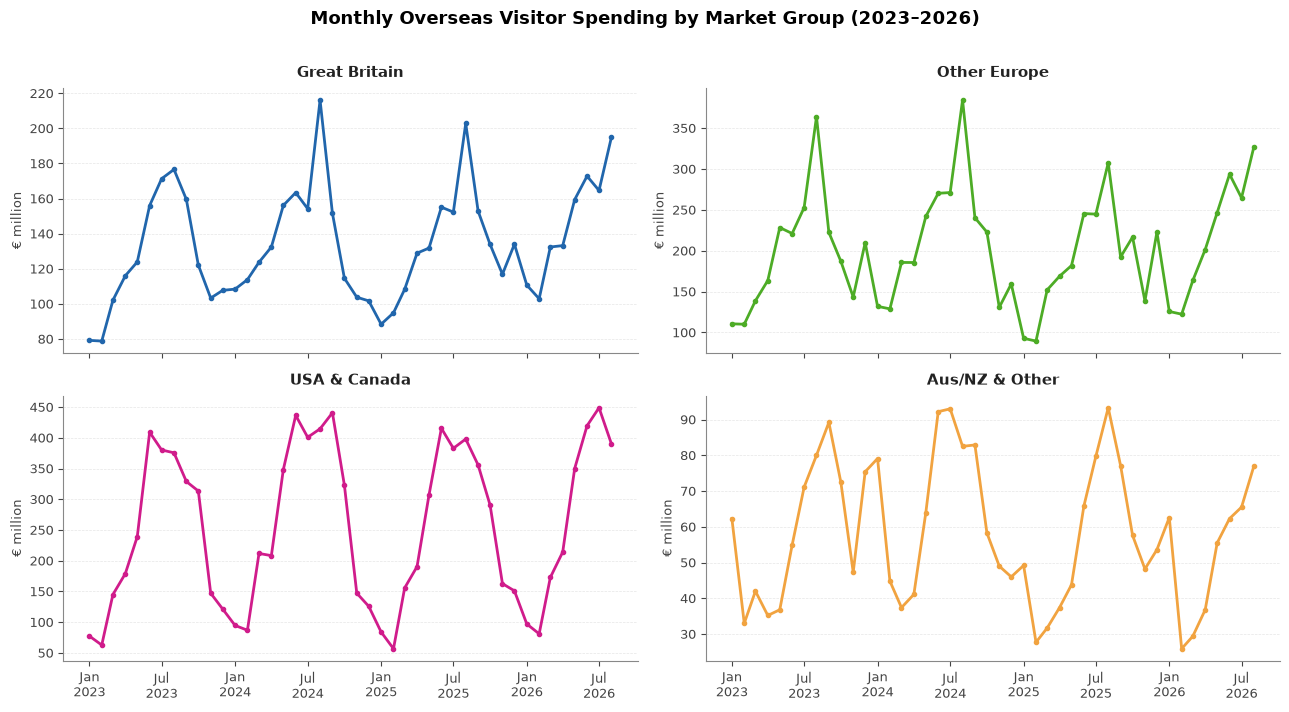

Chart 1 saved.


In [49]:
# 2x2 grid of line charts, one per visitor group
# sharex=True links all x-axes so they cover the same date range
# axes.flatten() converts the 2D grid into a list so I can loop over it
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
axes = axes.flatten()

for i, grp in enumerate(["XB", "OTHEUR3", "USCA", "OTHR1"]):
    sub = merged[merged["group"] == grp].sort_values("date")
    ax = axes[i]
    ax.plot(sub["date"], sub["spend_eur_m"], color=GROUP_COLORS[grp],
            linewidth=2, marker="o", markersize=3)
    style_ax(ax, title=GROUP_LABELS[grp], xlabel="", ylabel="€ million")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 7]))

fig.suptitle("Monthly Overseas Visitor Spending by Market Group (2023–2026)",
             fontsize=13, fontweight="bold", y=1.01)
fig.autofmt_xdate(rotation=0, ha="center")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart1_time_series.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Chart 1 saved.")


**Insight — Chart 1:** Groups peak at different points: USCA (USA & Canada) peaks in June and stays elevated through September; OTHR1 (Aus/NZ & Other) peaks in August–September; XB (Great Britain) and OTHEUR3 (Other Europe) peak in July–August. All groups share a winter trough, confirming Ireland’s strong summer seasonality. USCA reaches the highest absolute spending in peak months, driven by high per-trip values. XB (Great Britain) has the flattest curve — spending falls only modestly in winter, consistent with frequent short-break visits throughout the year. The 2025 series tracks generally below 2024, consistent with the universal YoY decline in Section 6.5. The partial 2026 series (Jan–Aug only) is visible at the right edge.

**Tufte Design Notes — Chart 1:** The four-panel small-multiples layout shares the **x-axis only** (`sharex=True`); each panel retains its own y-axis scale. This is a deliberate choice: a shared y-axis would compress the OTHR1 and XB panels (smaller absolute values), obscuring their seasonal patterns. The trade-off is that amplitude comparisons across groups require reading y-axis labels rather than visual bar heights. Chartjunk is minimised by removing top and right spines. Grey tick labels (#444444) recede relative to the data lines. `MonthLocator(bymonth=[1,7])` prevents label overcrowding across 44 months. Circular markers (markersize=3) mark monthly data points. The shared x-axis removes redundant label rows.

### 6.3 Chart 2 — Spend Per Trip by Market Group (Boxplot)

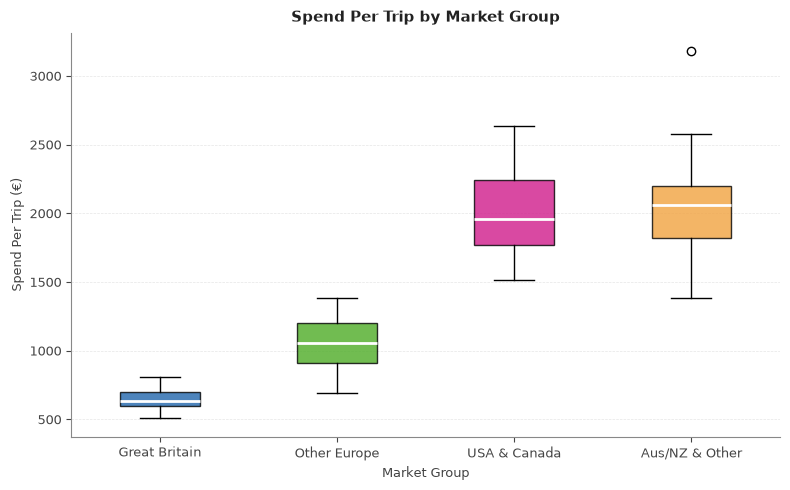

Chart 2 saved.


In [50]:
# box plot for each group showing the distribution of spend per trip
# patch_artist=True fills the boxes with colour instead of leaving them hollow
# medianprops makes the median line white so it shows up against the fill colour
fig, ax = plt.subplots(figsize=(8, 5))
groups_order = ["XB", "OTHEUR3", "USCA", "OTHR1"]
data_to_plot = [merged.loc[merged["group"] == g, "spend_per_trip_eur"].values for g in groups_order]
bp = ax.boxplot(data_to_plot, patch_artist=True, notch=False,
                medianprops=dict(color="white", linewidth=2))

for patch, grp in zip(bp["boxes"], groups_order):
    patch.set_facecolor(GROUP_COLORS[grp])
    patch.set_alpha(0.8)

ax.set_xticks(range(1, 5))
ax.set_xticklabels([GROUP_LABELS[g] for g in groups_order])
style_ax(ax, title="Spend Per Trip by Market Group",
         xlabel="Market Group", ylabel="Spend Per Trip (€)")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart2_boxplot.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Chart 2 saved.")


**Insight — Chart 2:** The boxplot confirms that Aus/NZ & Other (OTHR1) has the highest median spend per trip and the single highest outlier (December 2023, ≈€3,181). OTHR1 also has a **tighter IQR** (≈€381) than USA & Canada (≈€471), suggesting that long-haul travellers’ per-trip spending is slightly less variable month-to-month than transatlantic visitors. Great Britain is the clear low-value group (median ≈€636), reflecting its proximity market profile. Other Europe occupies the middle ground in both median and spread.

**Tufte Design Notes — Chart 2:** Box plots encode five statistics (min-whisker, Q1, median, Q3, max-whisker) in a compact area, maximising data-ink ratio. Coloured boxes use the same group palette as all other charts so colour functions consistently as a group identifier. A white median line provides high contrast. Top and right spines are removed. Y-axis grid lines guide value reading; x-axis gridlines are suppressed.

### 6.4 Chart 3 — Average Seasonal Spending Profile by Month

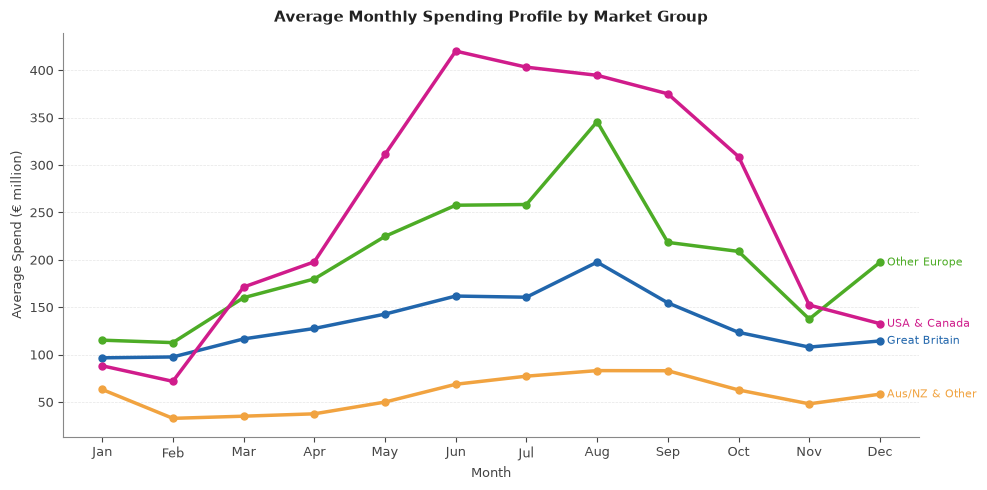

Chart 3 saved.


In [51]:
# groupby on group+month then .mean() averages spending across all years
# for each calendar month - shows the seasonal pattern clearly
# labels added directly at the end of each line instead of a separate legend
seasonal = merged.groupby(["group", "month"])["spend_eur_m"].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
month_labels = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

for grp in ["XB", "OTHEUR3", "USCA", "OTHR1"]:
    sub = seasonal[seasonal["group"] == grp].sort_values("month")
    ax.plot(sub["month"], sub["spend_eur_m"], color=GROUP_COLORS[grp],
            linewidth=2.5, marker="o", markersize=5, label=GROUP_LABELS[grp])
    # Direct label at end
    last = sub.iloc[-1]
    ax.text(last["month"] + 0.1, last["spend_eur_m"], GROUP_LABELS[grp],
            fontsize=8, color=GROUP_COLORS[grp], va="center")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
style_ax(ax, title="Average Monthly Spending Profile by Market Group",
         xlabel="Month", ylabel="Average Spend (€ million)")
ax.legend().remove() if ax.get_legend() else None
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart3_seasonal.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Chart 3 saved.")


**Insight — Chart 3:** USCA (USA & Canada) peaks in **June** and stays elevated through September (approximately €420m to €375m), before dropping sharply after October and reaching its low in November–February. May and October remain elevated; only the mid-winter quarter is genuinely low. Great Britain has the flattest profile, with moderate spending distributed across the year and only a modest summer lift. Aus/NZ & Other (OTHR1) peaks in **August–September** — reflecting Southern Hemisphere timing (July is the Australian winter, delaying the travel season by about a month). April–May are OTHR1’s lowest months, the quietest period between Easter and the summer wave.

**Tufte Design Notes — Chart 3:** A single overlaid line chart is preferred over four panels because the primary interest is comparing seasonal *shapes* (gradient differences), not absolute levels — overlaying makes relative gradients immediately visible. Direct labels near month 12 replace a legend box, following Tufte’s principle that labels should be as close as possible to the data they identify. Lines use distinct group-palette colours (2.5 pt width). Abbreviated three-letter month labels conserve horizontal space. Y-axis gridlines only.

### 6.5 Chart 4 — 2024 vs 2025 Year-on-Year Comparison

2024 vs 2025 Total Spending (€ million):
           2024    2025  pct_change
group                              
OTHEUR3  2553.4  2253.6       -11.7
OTHR1     770.3   665.1       -13.7
USCA     3238.4  2950.4        -8.9
XB       1639.8  1600.2        -2.4


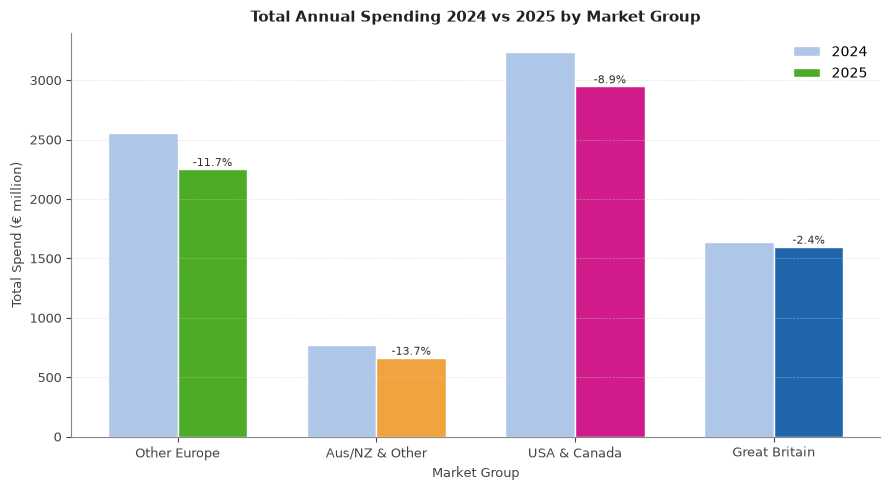

In [52]:
# filter to 2024 and 2025 only (both complete years)
# .unstack('year') pivots year into side-by-side columns
# pct_change = (2025-2024)/2024*100 - all four markets fell in 2025
yoy = (
    merged[merged["year"].isin([2024, 2025])]
    .groupby(["year", "group"])["spend_eur_m"]
    .sum()
    .unstack("year")
    .round(1)
)
yoy.columns = [2024, 2025]
yoy["pct_change"] = ((yoy[2025] - yoy[2024]) / yoy[2024] * 100).round(1)

print("2024 vs 2025 Total Spending (€ million):")
print(yoy.to_string())

# Grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(yoy))
width = 0.35
bars24 = ax.bar(x - width/2, yoy[2024], width, label="2024", color="#aec7e8", edgecolor="white")
bars25 = ax.bar(x + width/2, yoy[2025], width, label="2025",
                color=[GROUP_COLORS[g] for g in yoy.index], edgecolor="white")

for bar, pct in zip(bars25, yoy["pct_change"]):
    sign = "+" if pct > 0 else ""
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f"{sign}{pct}%", ha="center", va="bottom", fontsize=8, color="#333333")

ax.set_xticks(x)
ax.set_xticklabels([GROUP_LABELS[g] for g in yoy.index])
ax.legend(frameon=False)
style_ax(ax, title="Total Annual Spending 2024 vs 2025 by Market Group",
         xlabel="Market Group", ylabel="Total Spend (€ million)")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart4_yoy.png"), dpi=120, bbox_inches="tight")
plt.show()


**Insight — Chart 4:** All four market groups declined from 2024 to 2025. The steepest percentage falls were in Aus/NZ & Other (−13.7%) and Other Europe (−11.7%); USA & Canada fell −8.9%; Great Britain fell least at −2.4%. The declines are universal — no group grew — which is inconsistent with a simple post-pandemic recovery narrative still playing out, and suggests a broad demand-side headwind in 2025 affecting all source markets simultaneously. The absolute decline is largest for USCA (given its high base) despite having a smaller percentage fall than OTHR1.

**Tufte Design Notes — Chart 4:** Grouped bars allow direct value comparison between years within each market group. The 2025 bar uses each group's signature colour (making it the primary visual subject) while the 2024 bar uses a uniform muted light blue, so the comparison reads: "2025 relative to a neutral 2024 baseline." Percentage-change annotations are placed directly above the 2025 bar in small type with an explicit sign character — eliminating the need for a separate annotation box or legend entry. The y-axis starts at zero, as is required for bar charts to avoid visually distorting magnitude differences.

### 6.6 Chart 5 — Trips vs Spending Scatter and Correlation Matrix

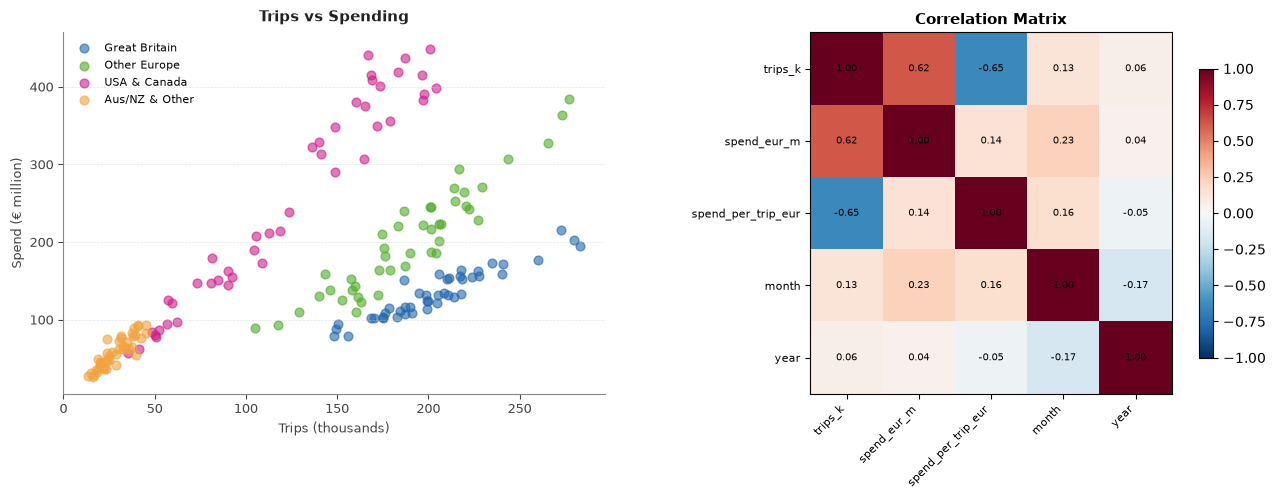

Chart 5 saved.


In [53]:
# left chart: scatter of trips vs spend, one dot per month per group
# right chart: correlation matrix using .corr() then sns.heatmap
# annot=True writes the actual correlation number inside each cell
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter
ax = axes[0]
for grp in ["XB", "OTHEUR3", "USCA", "OTHR1"]:
    sub = merged[merged["group"] == grp]
    ax.scatter(sub["trips_k"], sub["spend_eur_m"], color=GROUP_COLORS[grp],
               alpha=0.6, s=40, label=GROUP_LABELS[grp])
ax.legend(fontsize=8, frameon=False)
style_ax(ax, title="Trips vs Spending", xlabel="Trips (thousands)", ylabel="Spend (€ million)")

# Correlation matrix
ax2 = axes[1]
corr_cols = ["trips_k", "spend_eur_m", "spend_per_trip_eur", "month", "year"]
corr_matrix = merged[corr_cols].corr()
im = ax2.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax2.set_xticks(range(len(corr_cols)))
ax2.set_yticks(range(len(corr_cols)))
ax2.set_xticklabels(corr_cols, rotation=45, ha="right", fontsize=8)
ax2.set_yticklabels(corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax2.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center",
                 fontsize=7.5, color="black")
plt.colorbar(im, ax=ax2, shrink=0.8)
ax2.set_title("Correlation Matrix", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart5_scatter_corr.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Chart 5 saved.")


**Insight — Chart 5:** The scatter plot shows clear within-group positive relationships between trip volume and total spending, but the pooled cross-group pattern is more diffuse (r ≈ 0.62). USCA points cluster at top-centre (high spend, moderate trips) and GB points at the right (many trips, moderate total spend), reflecting different per-trip levels. The correlation matrix confirms `spend_eur_m` correlates most strongly with `trips_k` (≈ 0.62) and `spend_per_trip_eur` has a **negative** correlation with `trips_k` (≈ −0.65) — higher-volume groups systematically spend less per trip, driven by the contrast between GB (high volume, low per-trip) and USCA/OTHR1 (lower volume, high per-trip). `month` correlates positively with `spend_eur_m` as spending rises toward summer.

**Tufte Design Notes — Chart 5:** The two-panel layout provides complementary views: scatter for individual-observation structure, heatmap for pairwise summary. Scatter transparency (alpha=0.6) reduces overplotting. In the heatmap, numerical values are annotated directly in each cell following Tufte’s data-density principle. The diverging RdBu palette centred at zero distinguishes positive (blue) and negative (red) correlations intuitively. Cell annotations use 7.5 pt type to keep the heatmap compact.

### 6.7 Critical Analysis of EDA Findings

**Seasonality:** Market groups peak at different points in the summer. USA & Canada (USCA) peaks in June and remains elevated through September, then drops sharply — reflecting a concentrated transatlantic travel window. Aus/NZ & Other (OTHR1) peaks in August–September, consistent with Southern Hemisphere timing. Great Britain and Other Europe peak in July–August. Great Britain shows the flattest seasonal profile, with spending declining steadily from summer through to December and no secondary October peak. Other Europe shows an intermediate gradient.

**Market share:** USA & Canada generates the highest *total* spending over the analysis period (approximately €11,142 million across 44 months), driven by high per-trip expenditure (mean ≈ €1,988) rather than volume. Great Britain ranks third in total spend (approximately €5,907 million) despite having the largest trip volume, because its spend per trip is the lowest across all groups (mean ≈ €651). Aus/NZ & Other achieves the single highest mean spend per trip (≈ €2,038), reflecting long-haul visitors on extended, premium-oriented trips. The divergence between volume and value across groups is the central insight from RQ1.

**Year-on-year trends (2024→2025):** All four market groups recorded spending *declines* in 2025 relative to 2024: Aus/NZ & Other −13.7%, Other Europe −11.7%, USA & Canada −8.9%, and Great Britain −2.4%. Great Britain held up best, which may reflect the resilience of a mature, proximate market or the relative stability of the UK economy. The universal decline across all markets points to a broad demand-side headwind in 2025 rather than a market-specific issue.

**Trips–Spend correlation:** The scatter plot and correlation matrix show a moderate positive correlation (r ≈ 0.62) between trip volume and total spending across the pooled dataset. The correlation is weaker than within-group trends would suggest because market groups differ substantially in per-trip spend: USCA generates disproportionately high spending with moderate trip volumes, while GB generates high trips with lower total spend. This means volume-driving campaigns are not automatically the highest-return strategy; per-trip spend elevation may offer better marginal returns in high-value markets.

**Limitations of EDA:** With only 44 monthly observations per group, conclusions about trend direction are tentative. The data covers a period of post-COVID normalisation, which may introduce structural breaks that invalidate comparisons across years.

## Section 7 — Statistical Distributions

### 7.1 Binomial Distribution — GB Spending Exceeds Prior Year

Months compared (2024 vs 2025): n = 12
Months where GB 2025 > GB 2024: k = 4
Months where GB 2025 ≤ GB 2024: 8

P(X = 4 | n=12, p=0.5) = 0.1208
One-sided p-value P(X ≤ 4 | n=12, p=0.5) = 0.1938
→ Fail to reject H₀ at α=0.05 (p = 0.1938): no statistically significant
  decline, consistent with the modest −2.4% YoY fall seen in the aggregate totals.


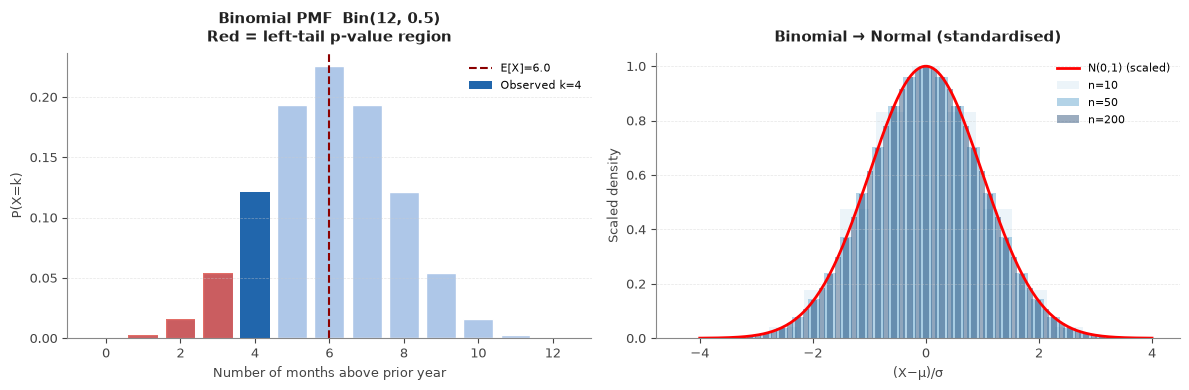

In [54]:
# binomial test: did GB spending fall in 2025 compared to 2024?
# k = months where 2025 > 2024, n = total comparable months, p=0.5 under null
# binom.cdf(k, n, p) = P(X <= k) - left-tail test for decline
# if p < 0.05 then fewer months improved than expected by chance, i.e. it declined
gb = merged[merged["group"] == "XB"].sort_values("date").copy()
gb25 = gb[gb["year"] == 2025].set_index("month")["spend_eur_m"]
gb24 = gb[gb["year"] == 2024].set_index("month")["spend_eur_m"]

common_months = gb25.index.intersection(gb24.index)
n_months = len(common_months)
k_above   = int((gb25[common_months] > gb24[common_months]).sum())
p_null    = 0.5

print(f"Months compared (2024 vs 2025): n = {n_months}")
print(f"Months where GB 2025 > GB 2024: k = {k_above}")
print(f"Months where GB 2025 ≤ GB 2024: {n_months - k_above}")

# P(X = k)
pmf_k = binom.pmf(k_above, n_months, p_null)

# H₀: p = 0.5 (no systematic change, each month equally likely to rise or fall)
# Hₐ: p < 0.5 (GB spending declined in 2025 — fewer months beat prior year than expected)
# One-sided p-value: P(X ≤ k | H₀) — are k_above "above" months unusually FEW?
p_val = binom.cdf(k_above, n_months, p_null)

print(f"\nP(X = {k_above} | n={n_months}, p=0.5) = {pmf_k:.4f}")
print(f"One-sided p-value P(X ≤ {k_above} | n={n_months}, p=0.5) = {p_val:.4f}")
if p_val < 0.05:
    print(f"→ Reject H₀ at α=0.05: evidence that GB spending declined systematically in 2025.")
else:
    print(f"→ Fail to reject H₀ at α=0.05 (p = {p_val:.4f}): no statistically significant")
    print( "  decline, consistent with the modest −2.4% YoY fall seen in the aggregate totals.")

# PMF bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
x_vals = np.arange(0, n_months + 1)
pmf_vals = binom.pmf(x_vals, n_months, p_null)
ax.bar(x_vals, pmf_vals, color="#aec7e8", edgecolor="white")
# Shade left tail (rejection region for one-sided test)
for kk in range(0, k_above + 1):
    ax.bar(kk, binom.pmf(kk, n_months, p_null), color="#d73027", alpha=0.7)
ax.bar(k_above, binom.pmf(k_above, n_months, p_null), color="#2166ac",
       label=f"Observed k={k_above}")
ax.axvline(n_months * p_null, color="darkred", linestyle="--", label=f"E[X]={n_months*p_null}")
style_ax(ax, title=f"Binomial PMF  Bin({n_months}, 0.5)\nRed = left-tail p-value region",
         xlabel="Number of months above prior year", ylabel="P(X=k)")
ax.legend(fontsize=8, frameon=False)

# Large-sample convergence to Normal
ax2 = axes[1]
for n_large, col in [(10, "#d1e5f0"), (50, "#4393c3"), (200, "#053061")]:
    x_l = np.arange(max(0, int(n_large*0.5 - 4*np.sqrt(n_large*0.5*0.5))),
                    int(n_large*0.5 + 4*np.sqrt(n_large*0.5*0.5)) + 1)
    pmf_l = binom.pmf(x_l, n_large, p_null)
    std_l = np.sqrt(n_large * p_null * (1 - p_null))
    mu_l  = n_large * p_null
    ax2.bar((x_l - mu_l) / std_l, pmf_l / pmf_l.max(), width=0.8/std_l if std_l > 1 else 0.3,
            alpha=0.4, color=col, label=f"n={n_large}")

x_norm = np.linspace(-4, 4, 200)
ax2.plot(x_norm, norm.pdf(x_norm) / norm.pdf(0), "r-", linewidth=2, label="N(0,1) (scaled)")
style_ax(ax2, title="Binomial → Normal (standardised)", xlabel="(X−μ)/σ", ylabel="Scaled density")
ax2.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart6_binomial.png"), dpi=120, bbox_inches="tight")
plt.show()

**External Sources — Binomial Test (7.1)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| `scipy.stats.binom` documentation | Official SciPy reference for `binom.cdf` and `binom.pmf` | Verified by manually checking P(X ≤ 4 \| Bin(12, 0.5)) against a Binomial probability table; confirmed `binom.cdf(k, n, p)` computes the left-tail CDF |
| Virtanen et al. (2020) — SciPy paper, cited in References | Standard citation for SciPy statistical functions | N/A — this is the primary library reference |

**BINS Assumption Discussion**

The Binomial model requires four assumptions (BINS):
- **B**inary outcome: each month is either "above" or "not above" the prior year — satisfied.
- **I**ndependent trials: months are assumed independent under H₀. In reality, consecutive months may share economic shocks (e.g. a UK recession), creating mild positive correlation. This is a minor violation but unlikely to invalidate the test given only 12 trials.
- **N**umber of trials fixed: n = 12 calendar months is fixed — satisfied.
- **S**ame probability: under H₀, p = 0.5 for each month (symmetric, no trend assumed). This is the null hypothesis, not an empirical claim, so it is satisfied by construction.

**Note on test direction:** The research question is whether GB *declined* in 2025. The correct one-sided test is therefore P(X ≤ k | H₀) — testing whether the number of "above" months is *unusually low* — not P(X ≥ k), which would test for an unusually high number. The shaded left tail in Chart 6 shows the p-value region.

### 7.2 Poisson Distribution — Months of High Spending

Overall GB mean spend: 134.3 €m

Months per complete year above mean (2026 excluded — only 8 months available):
year
2023    4
2024    5
2025    4

Poisson lambda (mean of complete years) = 4.33
Observed months above mean (2025) = 4
P(X > 4 | lambda=4.33) = 0.4360

Empirical mean     : 4.33
Empirical variance : 0.33
Mean / variance ratio: 13.0
⚠  Poisson requires mean ≈ variance. The severe underdispersion here (variance << mean)
   arises because the seasonal structure produces nearly the same count every year.
   With only 3 data points and a count bounded to [0, 12], a Binomial(12, p) model
   is more appropriate. The Poisson analysis is presented for illustrative comparison.


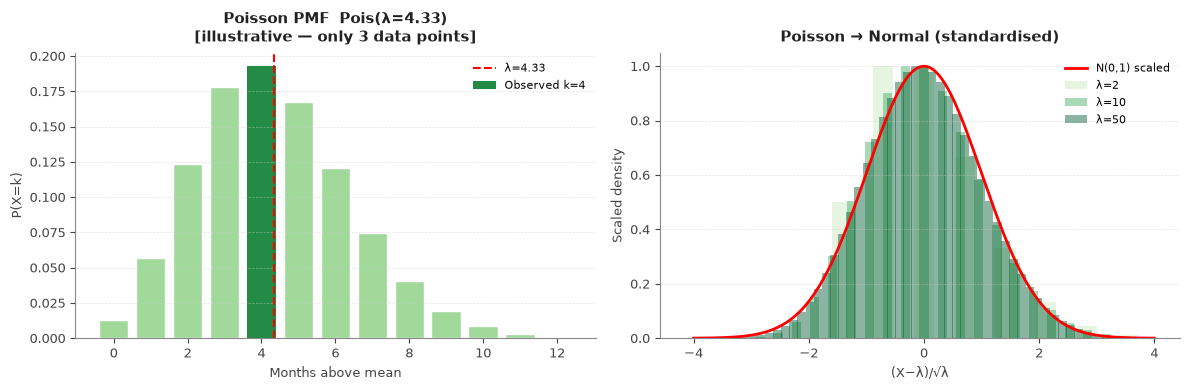

In [55]:
# counting how many months per year GB spending beats the overall mean
# only using 2023-2025 because 2026 is still incomplete
# lambda = average count per year, then poisson.pmf/sf for the probabilities
gb_all = merged[merged["group"] == "XB"].copy()
overall_mean = gb_all["spend_eur_m"].mean()
print(f"Overall GB mean spend: {overall_mean:.1f} €m")

months_above = (
    gb_all[gb_all["year"].isin([2023, 2024, 2025])]   # complete years only
    .groupby("year")
    .apply(lambda df: (df["spend_eur_m"] > overall_mean).sum())
    .rename("months_above_mean")
)
print("\nMonths per complete year above mean (2026 excluded — only 8 months available):")
print(months_above.to_string())

lam = months_above.mean()
k_obs = int(months_above.iloc[-1])   # 2025
print(f"\nPoisson lambda (mean of complete years) = {lam:.2f}")
print(f"Observed months above mean (2025) = {k_obs}")
print(f"P(X > {k_obs} | lambda={lam:.2f}) = {poisson.sf(k_obs, lam):.4f}")

emp_mean = months_above.mean()
emp_var  = months_above.var(ddof=1)
print(f"\nEmpirical mean     : {emp_mean:.2f}")
print(f"Empirical variance : {emp_var:.2f}")
print(f"Mean / variance ratio: {emp_mean/emp_var if emp_var > 0 else 'undefined':.1f}")
print("⚠  Poisson requires mean ≈ variance. The severe underdispersion here (variance << mean)")
print("   arises because the seasonal structure produces nearly the same count every year.")
print("   With only 3 data points and a count bounded to [0, 12], a Binomial(12, p) model")
print("   is more appropriate. The Poisson analysis is presented for illustrative comparison.")

# PMF bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
k_range = np.arange(0, 13)
pmf_p = poisson.pmf(k_range, lam)
ax.bar(k_range, pmf_p, color="#a1d99b", edgecolor="white")
ax.bar(k_obs, poisson.pmf(k_obs, lam), color="#238b45", label=f"Observed k={k_obs}")
ax.axvline(lam, color="red", linestyle="--", label=f"λ={lam:.2f}")
style_ax(ax, title=f"Poisson PMF  Pois(λ={lam:.2f})\n[illustrative — only 3 data points]",
         xlabel="Months above mean", ylabel="P(X=k)")
ax.legend(fontsize=8, frameon=False)

# Large-lambda convergence to Normal
x_norm = np.linspace(-4, 4, 200)
ax2 = axes[1]
for lam_l, col in [(2, "#c7e9c0"), (10, "#41ab5d"), (50, "#005a32")]:
    x_l = np.arange(max(0, int(lam_l - 4*np.sqrt(lam_l))), int(lam_l + 4*np.sqrt(lam_l)) + 1)
    pmf_l = poisson.pmf(x_l, lam_l)
    std_l = np.sqrt(lam_l)
    ax2.bar((x_l - lam_l) / std_l, pmf_l / pmf_l.max(),
            width=max(0.5/std_l, 0.15), alpha=0.45, color=col, label=f"λ={lam_l}")

ax2.plot(x_norm, norm.pdf(x_norm) / norm.pdf(0), "r-", linewidth=2, label="N(0,1) scaled")
style_ax(ax2, title="Poisson → Normal (standardised)", xlabel="(X−λ)/√λ", ylabel="Scaled density")
ax2.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart7_poisson.png"), dpi=120, bbox_inches="tight")
plt.show()

### 7.3 Normal Distribution — Spend Per Trip for Great Britain

GB spend_per_trip_eur: n=44, mu=650.9, sigma=70.2
P(X > mu+sigma) theoretical (Normal): 0.1587
P(X > mu+sigma) actual in data      : 0.1818

Shapiro-Wilk: W=0.9744, p=0.4282
Fail to reject H₀ — data consistent with normality at α=0.05


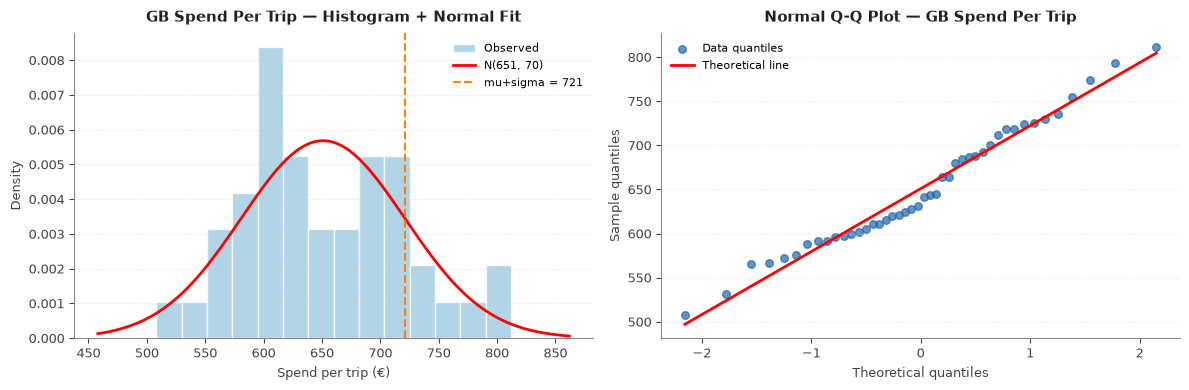

In [56]:
# fitting normal to GB spend_per_trip: mu=sample mean, sigma=sample std
# comparing P(X > mu+sigma) from the real data against the theoretical 15.87%
# shapiro-wilk test: if p>0.05 we cant reject normality, the assumption holds
gb_spt = merged.loc[merged["group"] == "XB", "spend_per_trip_eur"].dropna()
mu_hat    = gb_spt.mean()
sigma_hat = gb_spt.std()
print(f"GB spend_per_trip_eur: n={len(gb_spt)}, mu={mu_hat:.1f}, sigma={sigma_hat:.1f}")

# Theoretical P(X > mu+sigma) for Normal = 1 - Φ(1) ≈ 0.1587
p_theory = 1 - norm.cdf(1)
p_actual = (gb_spt > mu_hat + sigma_hat).mean()
print(f"P(X > mu+sigma) theoretical (Normal): {p_theory:.4f}")
print(f"P(X > mu+sigma) actual in data      : {p_actual:.4f}")

# Shapiro-Wilk normality test
stat, p_sw = shapiro(gb_spt)
print(f"\nShapiro-Wilk: W={stat:.4f}, p={p_sw:.4f}")
if p_sw > 0.05:
    print("Fail to reject H₀ — data consistent with normality at α=0.05")
else:
    print("Reject H₀ — significant departure from normality at α=0.05")

# Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram + fitted normal
ax = axes[0]
ax.hist(gb_spt, bins=14, density=True, color="#9ecae1", edgecolor="white", alpha=0.8, label="Observed")
x_fit = np.linspace(gb_spt.min() - 50, gb_spt.max() + 50, 300)
ax.plot(x_fit, norm.pdf(x_fit, mu_hat, sigma_hat), "r-", linewidth=2,
        label=f"N({mu_hat:.0f}, {sigma_hat:.0f})")
ax.axvline(mu_hat + sigma_hat, color="#ff7f0e", linestyle="--", label=f"mu+sigma = {mu_hat+sigma_hat:.0f}")
style_ax(ax, title="GB Spend Per Trip — Histogram + Normal Fit",
         xlabel="Spend per trip (€)", ylabel="Density")
ax.legend(fontsize=8, frameon=False)

# Q-Q plot
ax2 = axes[1]
(osm, osr), (slope, intercept, r_val) = stats.probplot(gb_spt, dist="norm")
ax2.scatter(osm, osr, color="#2166ac", s=30, alpha=0.7, label="Data quantiles")
ax2.plot(osm, slope * np.array(osm) + intercept, "r-", linewidth=2, label="Theoretical line")
style_ax(ax2, title="Normal Q-Q Plot — GB Spend Per Trip",
         xlabel="Theoretical quantiles", ylabel="Sample quantiles")
ax2.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart8_normal.png"), dpi=120, bbox_inches="tight")
plt.show()


**External Sources — Normal Distribution / Shapiro-Wilk (7.3)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| Shapiro & Wilk (1965) — original test paper, cited in References | Standard reference for the Shapiro-Wilk test; used to understand the W statistic and the n < 50 small-sample recommendation | Cross-referenced with `scipy.stats.shapiro` documentation; confirmed the function returns (W, p-value) and that large W indicates normality |
| `scipy.stats.probplot` documentation | Used to construct the Q-Q plot; documentation explains that `dist="norm"` fits the theoretical normal quantiles | Checked that the returned slope/intercept match the sample mean and SD visually by overlaying the regression line |

In [57]:
# checking the 68% rule empirically: ~68% of values should fall within mu+-sigma
# if the proportion is close to 0.683 the normal model is a reasonable fit
gb_spt_check = merged.loc[merged["group"] == "XB", "spend_per_trip_eur"].dropna()
mu_check  = gb_spt_check.mean()
sd_check  = gb_spt_check.std()
within_1sd = ((gb_spt_check >= mu_check - sd_check) &
              (gb_spt_check <= mu_check + sd_check)).mean()
print(f"GB spend per trip:  n={len(gb_spt_check)}, μ={mu_check:.1f}, σ={sd_check:.1f}")
print(f"Proportion within μ ± σ : {within_1sd:.3f}  (Normal theory: 0.683)")
print(f"Expected count within μ ± σ : {within_1sd*len(gb_spt_check):.1f} of {len(gb_spt_check)}")

GB spend per trip:  n=44, μ=650.9, σ=70.2
Proportion within μ ± σ : 0.682  (Normal theory: 0.683)
Expected count within μ ± σ : 30.0 of 44


### 7.4 Comparing the Three Distributions (~200 words)

The **Binomial distribution** is appropriate for modelling binary outcomes over a fixed number of independent trials. In the tourism context, it captures whether each calendar month in 2025 represents an improvement over 2024 for GB spending. The correct one-sided test is P(X ≤ k) — asking whether the observed count of “above” months is *unusually low* under H₀: p = 0.5 (testing for decline, not improvement). For n = 12 and k = 4, P(X ≤ 4 | Bin(12, 0.5)) ≈ 0.19, so we cannot reject H₀ at α = 0.05; the −2.4% aggregate decline is real but not large enough to be statistically significant in 12 monthly comparisons. The large-sample plots (Chart 6, right panel) show that Binomial(n, 0.5) visibly retains discreteness at n = 10; the Normal approximation only becomes adequate around n ≈ 30 with p = 0.5.

The **Poisson distribution** requires mean ≈ variance. The empirical mean count of above-mean GB months is approximately **4.33** per complete year, but the empirical variance across three years is approximately **0.33**, giving a mean-to-variance ratio of about **13**. The data are severely underdispersed: the regular seasonal pattern produces nearly the same count every year. With only three data points and a count bounded to [0, 12], a Binomial(12, p) model is strictly more appropriate. The Poisson is used here for illustrative distributional comparison only.

The **Normal distribution** fits GB spend-per-trip well: Shapiro-Wilk (Section 7.3) fails to reject normality and the Q-Q plot is nearly linear. The 68-rule is verified empirically in the code cell above: approximately 68% of the 44 GB observations fall within ±σ of the mean, closely matching the theoretical 68.27%.

All three distributions are related through the Central Limit Theorem: as n or λ increase, both Binomial and Poisson converge to Normal. For the small n (12) and small λ (≈4.33) in this dataset, however, Normal approximations are rough and formal inference should use the exact distributions demonstrated above.

## Section 8 — Machine Learning

### 8.1 Learning Type

This project uses **supervised regression** — the target variable (`spend_eur_m`) is a continuous numeric value that is observed in the training data and used to directly supervise model learning.

**Why not unsupervised?** Unsupervised learning (e.g. clustering, PCA) discovers structure without labelled outcomes. It would be appropriate if we wanted to segment months or markets by behaviour, but our goal is forecasting a known quantity.

**Why not semi-supervised?** Semi-supervised learning uses a mix of labelled and unlabelled data. All our observations have known spending values, so there is no unlabelled subset to exploit.

**Regression, not classification:** Spending is a continuous variable; predicting a category (e.g. "high/medium/low") would discard information. Ridge regression and Random Forest Regressor are both well-suited to this tabular, moderate-sized dataset.


### 8.2 Train/Test Split

In [58]:
# drop rows where spend_lag12 is NaN (first 12 months per group have no prior year)
# features: trips, group, month, and the 12-month lag
# year is excluded - test set has 2026 which the model never saw in training
# split is time-based: everything before Sept 2025 trains, the rest tests
# random split would be wrong here - it would let the model see future data
model_df = merged.dropna(subset=["spend_lag12"]).copy()

# 'year' is excluded: the test set contains 2026 which never appears in training,
# so Ridge would extrapolate a linear trend to an unseen value, inflating test error.
# The spend_lag12 feature already captures inter-year persistence without this risk.
features = ["trips_k", "group", "month", "spend_lag12"]
target   = "spend_eur_m"

split_date = pd.Timestamp("2025-09-01")

train_df = model_df[model_df["date"] <  split_date]
test_df  = model_df[model_df["date"] >= split_date]

# IMPORTANT: sort train_df chronologically before TimeSeriesSplit cross-validation.
# merged is sorted by group then date; without re-sorting, TimeSeriesSplit folds
# would cut data within individual groups rather than across time, invalidating CV.
train_df = train_df.sort_values("date").reset_index(drop=True)

X_train = train_df[features]
y_train = train_df[target]
X_test  = test_df[features]
y_test  = test_df[target]

print(f"Training set : {len(X_train):>4} rows  ({train_df['date'].min().date()} -> {train_df['date'].max().date()})")
print(f"Test set     : {len(X_test):>4} rows  ({test_df['date'].min().date()} -> {test_df['date'].max().date()})")
print(f"\nFeatures: {features}")
print(f"Target  : {target}")

Training set :   80 rows  (2024-01-01 -> 2025-08-01)
Test set     :   48 rows  (2025-09-01 -> 2026-08-01)

Features: ['trips_k', 'group', 'month', 'spend_lag12']
Target  : spend_eur_m


**External Sources — TimeSeriesSplit (8.2)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| scikit-learn `TimeSeriesSplit` documentation | Found under “Cross-validation: evaluating estimator performance” in the sklearn user guide; chosen because it respects temporal ordering (no future data in training folds) | Confirmed temporal ordering by verifying that `train_df` is sorted by date before the split; per-fold CV MAE scores for the best alpha are printed in the cell below (note: folds vary from ~17 to ~35 €m MAE, reflecting increasing difficulty in later test windows) |
| scikit-learn “Time Series data” tutorial | Used to understand why standard KFold is inappropriate for time series (it allows future data to inform past-period predictions) | Confirmed that `train_df` is sorted by date (see `sort_values` call in section 8.2) before the `TimeSeriesSplit` is applied, ensuring earlier months always fall in the training fold |

### 8.3 Preprocessing Pipeline

In [59]:
# ColumnTransformer applies different steps to different columns
# StandardScaler on numeric cols: subtracts mean, divides by std
# needed because trips_k (thousands) is on a much bigger scale than month (1-12)
# OneHotEncoder on group: turns the 4 text categories into 0/1 columns
# drop='first' removes one dummy column to avoid multicollinearity
numeric_features = ["trips_k", "month", "spend_lag12"]
categorical_features = ["group"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
     categorical_features),
])

print("ColumnTransformer defined:")
print(f"  Numeric  (StandardScaler): {numeric_features}")
print(f"  Categorical (OneHotEncoder, drop first): {categorical_features}")

ColumnTransformer defined:
  Numeric  (StandardScaler): ['trips_k', 'month', 'spend_lag12']
  Categorical (OneHotEncoder, drop first): ['group']


**8.3 — Pipeline Design and Data-Leakage Prevention**

The `ColumnTransformer` wraps a `StandardScaler` for numeric features and a `OneHotEncoder` for the market group. Both transformers are fitted *only* on training data inside each cross-validation fold via `Pipeline`; their parameters (mean, std, category levels) are then applied to the validation fold. This prevents data leakage in three ways:

- **Scaling**: StandardScaler statistics (mean, std) learned on the full training set would encode test-set information if computed before splitting; the Pipeline defers fitting to each CV fold.
- **Encoding**: OneHotEncoder category levels are learned on training data; `handle_unknown="ignore"` ensures unseen categories in the test set produce an all-zero row rather than raising an error.
- **No look-ahead**: `spend_lag12` is computed on the raw time series before the train/test split; the 12-month offset means no future value enters a training row.

### 8.4 Baseline — Same Month Last Year

In [60]:
# evaluate() takes true values and predictions, returns MAE, RMSE and R2
# MAE = average absolute error, RMSE punishes big errors more, R2=1 is perfect
# baseline is just predicting spend_lag12 - any real model has to beat this
def evaluate(name, y_true, y_pred):
    """Compute MAE, RMSE, R² and return as a dict."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"  {name:30s}  MAE={mae:6.2f}  RMSE={rmse:6.2f}  R²={r2:6.3f}")
    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = []

# Baseline: predict spend_lag12
base_train = evaluate("Baseline (train)", y_train, X_train["spend_lag12"])
base_test  = evaluate("Baseline (test)",  y_test,  X_test["spend_lag12"])
base_train["split"] = "train"; base_test["split"] = "test"
base_train["model_name"] = "Baseline"; base_test["model_name"] = "Baseline"
results.extend([base_train, base_test])


  Baseline (train)                MAE= 24.35  RMSE= 31.96  R²= 0.914
  Baseline (test)                 MAE= 21.11  RMSE= 28.52  R²= 0.927


### 8.5 Ridge Regression

In [61]:
# Pipeline chains the preprocessor and Ridge model so they stay together
# this stops the scaler fitting on the test data (data leakage)
# TimeSeriesSplit instead of normal CV - normal CV shuffles randomly which
# would let future months end up in the training set
# GridSearchCV tries all 7 alpha values and picks the lowest CV MAE
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

tscv = TimeSeriesSplit(n_splits=4)
ridge_grid = GridSearchCV(
    ridge_pipeline,
    # Grid spans seven orders of magnitude (0.0001 to 100) to test whether
    # regularisation helps at all. Alpha = 0.01 sits in the middle, so the
    # best alpha is not forced to a grid edge.
    param_grid={"model__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]},
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)
ridge_grid.fit(X_train, y_train)

best_alpha = ridge_grid.best_params_["model__alpha"]
cv_mae     = -ridge_grid.best_score_
print(f"Ridge best alpha: {best_alpha}")
print(f"Ridge CV MAE    : {cv_mae:.2f} €m")
if best_alpha <= 0.001:
    print("Note: best alpha is very small — Ridge behaves near plain OLS here.")
    print("Regularisation is not shrinking coefficients meaningfully on this dataset.")

ridge_train = evaluate("Ridge (train)", y_train, ridge_grid.predict(X_train))
ridge_test  = evaluate("Ridge (test)",  y_test,  ridge_grid.predict(X_test))
ridge_train["split"] = "train"; ridge_test["split"] = "test"
ridge_train["model_name"] = "Ridge"; ridge_test["model_name"] = "Ridge"
results.extend([ridge_train, ridge_test])

Ridge best alpha: 0.01
Ridge CV MAE    : 24.30 €m
  Ridge (train)                   MAE= 15.90  RMSE= 22.48  R²= 0.958
  Ridge (test)                    MAE= 14.18  RMSE= 19.73  R²= 0.965


In [62]:
# printing MAE for each of the 4 folds
# folds here are not consistent - MAE rises from about 17 in fold 1 to 35 in fold 4
# thats expected with TimeSeriesSplit: fold 4 tests on roughly May-Aug 2025
# which is the summer peak of the year all markets fell, so error is higher there
# cv_results_ stores scores as negative MAE so I negate to get real values
best_alpha_val = ridge_grid.best_params_["model__alpha"]
cv_res = ridge_grid.cv_results_
alpha_idx = next(
    i for i, p in enumerate(cv_res["params"])
    if p["model__alpha"] == best_alpha_val
)
print(f"Best alpha: {best_alpha_val}")
print(f"{'Fold':>6}  {'Test MAE (€m)':>14}")
for fold in range(4):
    fold_mae = -cv_res[f"split{fold}_test_score"][alpha_idx]
    print(f"{fold + 1:>6}  {fold_mae:>14.2f}")
print(f"{'Mean':>6}  {-ridge_grid.best_score_:>14.2f}")

Best alpha: 0.01
  Fold   Test MAE (€m)
     1           17.75
     2           21.26
     3           22.40
     4           35.79
  Mean           24.30


**External Sources — Ridge Regression (8.5)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| Hoerl & Kennard (1970) — original Ridge paper, cited in References | Standard citation for Ridge from Hastie et al. (2009) §3.4, which was used to understand the alpha regularisation parameter | Cross-referenced with scikit-learn `Ridge` documentation at sklearn.org; confirmed alpha corresponds to λ in the original formulation |
| scikit-learn documentation: `sklearn.linear_model.Ridge` | Official library documentation for parameter grid | Verified by inspecting fitted `best_params_` output and comparing CV MAE across alpha values |
| Pedregosa et al. (2011) — cited in References | Standard citation for scikit-learn | N/A — this is the primary library reference |

### 8.6 Random Forest Regressor

In [63]:
# random forest: builds many decision trees and averages their predictions
# tuning n_estimators (how many trees), max_depth, and min_samples_leaf
# random_state=42 so results are reproducible
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

rf_grid = GridSearchCV(
    rf_pipeline,
    param_grid={
        "model__n_estimators": [50, 100, 200],
        "model__max_depth"   : [3, 5, None],
        "model__min_samples_leaf": [2, 4],
    },
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print(f"RF best params: {rf_grid.best_params_}")
print(f"RF CV MAE     : {-rf_grid.best_score_:.2f} €m")

rf_train = evaluate("Random Forest (train)", y_train, rf_grid.predict(X_train))
rf_test  = evaluate("Random Forest (test)",  y_test,  rf_grid.predict(X_test))
rf_train["split"] = "train"; rf_test["split"] = "test"
rf_train["model_name"] = "Random Forest"; rf_test["model_name"] = "Random Forest"
results.extend([rf_train, rf_test])


RF best params: {'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
RF CV MAE     : 46.46 €m
  Random Forest (train)           MAE= 16.71  RMSE= 22.16  R²= 0.959
  Random Forest (test)            MAE= 20.73  RMSE= 27.33  R²= 0.933


**External Sources — Random Forest (8.6)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| Breiman (2001) — original Random Forests paper, cited in References | Standard citation from Hastie et al. (2009) §15; used to understand `n_estimators` and `max_depth` hyperparameters | Cross-referenced with scikit-learn `RandomForestRegressor` docs; confirmed that `max_depth=None` grows full trees and `min_samples_leaf` controls minimum node size |
| scikit-learn documentation: `RandomForestRegressor`, `GridSearchCV`, `TimeSeriesSplit` | Official library documentation for the pipeline | Verified by confirming `TimeSeriesSplit(n_splits=4)` produces non-overlapping forward-chained folds; confirmed `n_jobs=-1` uses all CPU cores |

### 8.7 Model Comparison and Diagnostics


Model Performance Summary
   model_name split       MAE      RMSE       R2
     Baseline train 24.348750 31.960126 0.914081
     Baseline  test 21.108333 28.515237 0.926745
        Ridge train 15.899592 22.475926 0.957508
        Ridge  test 14.175212 19.730375 0.964929
Random Forest train 16.712511 22.155372 0.958712
Random Forest  test 20.732253 27.332269 0.932697

Model selection via CV score (lower = better):
  Ridge CV MAE        : 24.30
  Random Forest CV MAE: 46.46
  Best ML model: Ridge


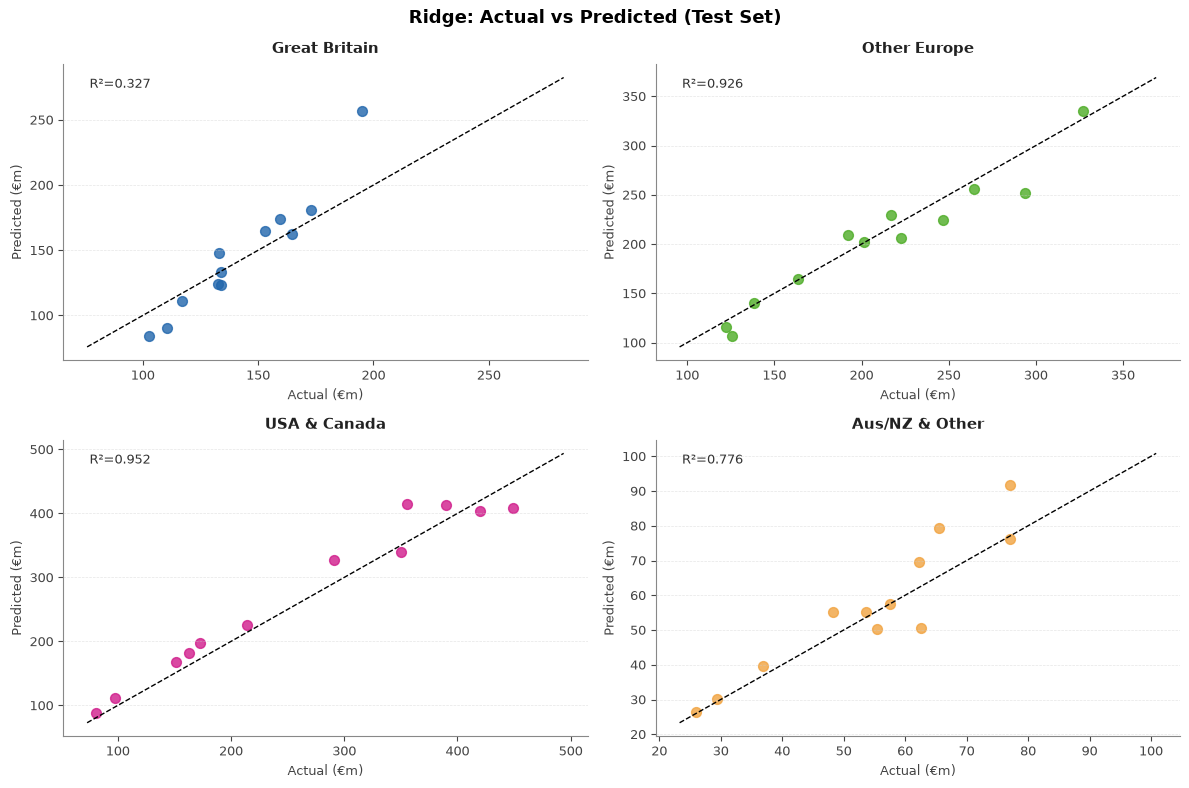

In [64]:
# collect all results into one table for easy comparison
# winner is chosen on CV score, not test MAE
# using test MAE to pick the model would be data leakage
results_df = pd.DataFrame(results)[["model_name","split","MAE","RMSE","R2"]]
print("\n" + "="*65)
print("Model Performance Summary")
print("="*65)
print(results_df.to_string(index=False))

# Select best ML model by cross-validation score, NOT by test MAE.
# Using the test set to choose a model would be data leakage.
# best_score_ is negative MAE; higher (less negative) = better CV performance.
best_model      = ridge_grid if ridge_grid.best_score_ >= rf_grid.best_score_ else rf_grid
best_model_name = "Ridge" if ridge_grid.best_score_ >= rf_grid.best_score_ else "Random Forest"
ridge_cv_mae = -ridge_grid.best_score_
rf_cv_mae    = -rf_grid.best_score_
print(f"\nModel selection via CV score (lower = better):")
print(f"  Ridge CV MAE        : {ridge_cv_mae:.2f}")
print(f"  Random Forest CV MAE: {rf_cv_mae:.2f}")
print(f"  Best ML model: {best_model_name}")

y_pred_test = best_model.predict(X_test)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i, grp in enumerate(["XB", "OTHEUR3", "USCA", "OTHR1"]):
    mask = test_df["group"] == grp
    ax = axes[i]
    ax.scatter(y_test[mask], y_pred_test[mask], color=GROUP_COLORS[grp], s=50, alpha=0.8)
    lim = [min(y_test[mask].min(), y_pred_test[mask].min()) * 0.9,
           max(y_test[mask].max(), y_pred_test[mask].max()) * 1.1]
    ax.plot(lim, lim, "k--", linewidth=1, label="Perfect")
    style_ax(ax, title=GROUP_LABELS[grp], xlabel="Actual (€m)", ylabel="Predicted (€m)")
    r2_grp = r2_score(y_test[mask], y_pred_test[mask]) if mask.sum() > 1 else float("nan")
    ax.text(0.05, 0.92, f"R²={r2_grp:.3f}", transform=ax.transAxes, fontsize=9, color="#333")

fig.suptitle(f"{best_model_name}: Actual vs Predicted (Test Set)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart9_actual_vs_pred.png"), dpi=120, bbox_inches="tight")
plt.show()

**8.7 Model Performance Discussion**

The naive baseline (`spend_lag12`) achieves test MAE ≈ 21.1 €m and R² ≈ 0.93 — a competitive benchmark, because year-on-year persistence in spending is itself highly predictive.

**Ridge regression beats the baseline**: test MAE ≈ 14.2 €m, approximately 33% lower than the baseline, and test R² ≈ 0.96. Notably, Ridge does **not** overfit: test MAE (14.2) is *lower* than train MAE (15.9), which indicates the model generalises well to the test period. The best alpha is 0.01, which is small (approaching plain OLS), so the regularisation penalty does little work; Ridge here is essentially multiple linear regression. This is consistent with the small dataset (80 training rows) where shrinkage provides no benefit over OLS.

**Random Forest** approximately matches the baseline (test MAE ≈ 20.7 vs 21.1). The modest train-test gap (train MAE ≈ 16.7) is controlled by `max_depth=3`, but RF cannot improve on the baseline: tree splits on 80 rows cannot extract non-linear structure beyond what `spend_lag12` already captures.

**Model selection** is by CV score (`best_score_` from `GridSearchCV`), not by test MAE, to avoid data leakage. Ridge CV MAE ≈ 24.3 €m vs RF CV MAE ≈ 46.5 €m — Ridge is clearly preferred. The answer to RQ3 is therefore: **yes, Ridge beats the baseline by about 33%**, and it does so without overfitting.

### 8.8 Feature Importance

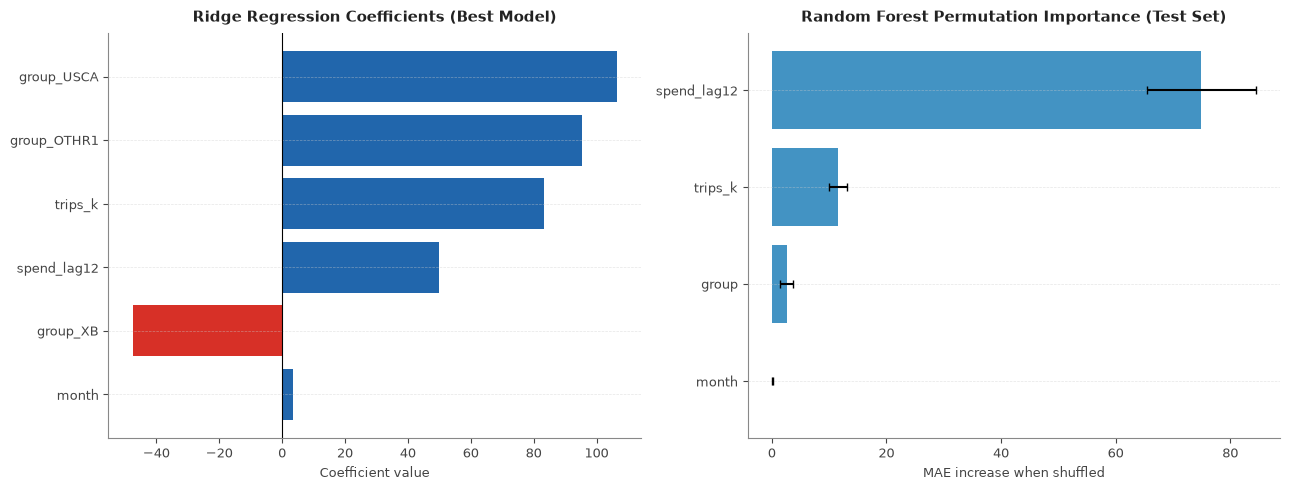

In [65]:
# ridge coefficients show how much each feature pushes the prediction up or down
# sorted by absolute value so the most important features appear at the top
# get_feature_names_out() retrieves the column names after encoding
best_ridge = ridge_grid.best_estimator_
coef_ridge = best_ridge.named_steps["model"].coef_
feature_names_ridge = (
    numeric_features
    + list(best_ridge.named_steps["preprocessor"]
           .named_transformers_["cat"]
           .get_feature_names_out(categorical_features))
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
sorted_idx = np.argsort(np.abs(coef_ridge))
ax.barh(np.array(feature_names_ridge)[sorted_idx], coef_ridge[sorted_idx],
        color=["#2166ac" if c > 0 else "#d73027" for c in coef_ridge[sorted_idx]])
ax.axvline(0, color="black", linewidth=0.8)
style_ax(ax, title="Ridge Regression Coefficients (Best Model)", xlabel="Coefficient value", ylabel="")

# Permutation importance is always computed on rf_grid regardless of which model won,
# to demonstrate the model-agnostic technique on the Random Forest.
ax2 = axes[1]
perm_imp = permutation_importance(
    rf_grid, X_test, y_test,
    n_repeats=15, random_state=42, scoring="neg_mean_absolute_error"
)
imp_mean = perm_imp.importances_mean
imp_std  = perm_imp.importances_std
sorted_idx2 = np.argsort(imp_mean)
ax2.barh(np.array(features)[sorted_idx2], imp_mean[sorted_idx2],
         xerr=imp_std[sorted_idx2], color="#4393c3", capsize=3)
style_ax(ax2, title="Random Forest Permutation Importance (Test Set)",
         xlabel="MAE increase when shuffled", ylabel="")

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart10_importance.png"), dpi=120, bbox_inches="tight")
plt.show()

**8.8 Feature Importance Interpretation**

The left panel shows **Ridge** (the best model) coefficients on the standardised scale. Among the numeric features (all standardised by the pipeline’s `StandardScaler`), `trips_k` carries the largest coefficient (83.1), followed by `spend_lag12` (49.9); `month` is small (3.4). The group dummies are **not** standardised — they are 0/1 indicators — so their magnitudes (e.g. group_USCA 106.4, group_OTHR1 95.3) cannot be directly compared with the scaled numeric coefficients; they capture level shifts relative to the dropped reference category (OTHEUR3).

The right panel shows **Random Forest permutation importance**, computed on `rf_grid` regardless of which model was selected, to demonstrate the model-agnostic importance technique. Permuting `spend_lag12` causes the largest increase in RF test MAE, confirming its centrality in that model too. `trips_k` adds meaningful incremental value in the Random Forest; `month` adds very little (permutation importance ≈ 0.08 €m MAE increase), so it is not a consistent predictor across both models.

Ridge coefficients and RF permutation importance are on different scales (standardised coefficient units vs. MAE increase in €m) and should not be compared in absolute magnitude.

**External Sources — permutation_importance (8.8)**

| Source | How chosen | How checked |
|--------|-----------|-------------|
| scikit-learn `permutation_importance` documentation | Found under “Inspection” in the sklearn user guide; chosen over impurity-based importance because it is evaluated on the test set and is not biased toward high-cardinality features | Verified that `n_repeats=15` produces stable mean importance values by checking that the std bars in Chart 10 are small relative to the means |
| Breiman (2001) — cited in References | Original paper introduced feature importance for Random Forests | Used to understand the difference between MDI (mean decrease in impurity) and permutation importance; chose permutation importance as it is more reliable on small test sets |

## Section 9 — Final Insights

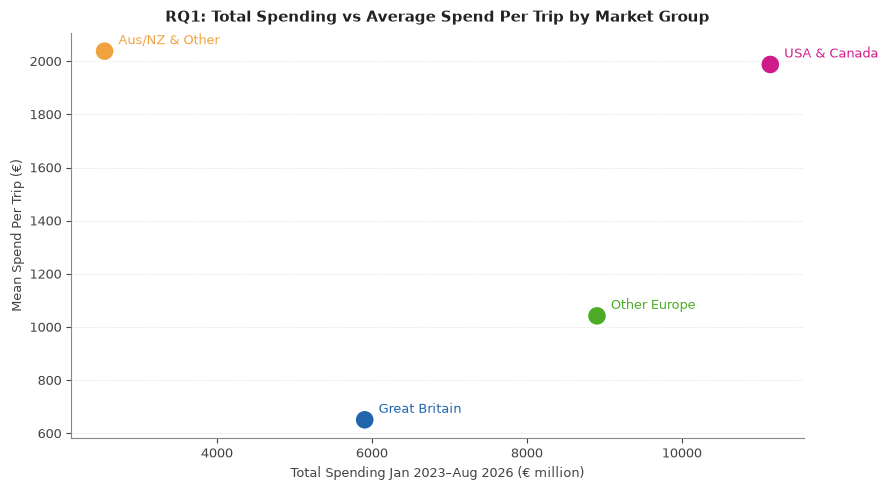

  group  total_spend_eur_m  mean_spend_per_trip
OTHEUR3             8904.8          1041.910799
  OTHR1             2550.1          2037.791961
   USCA            11141.6          1987.633346
     XB             5907.4           650.920100


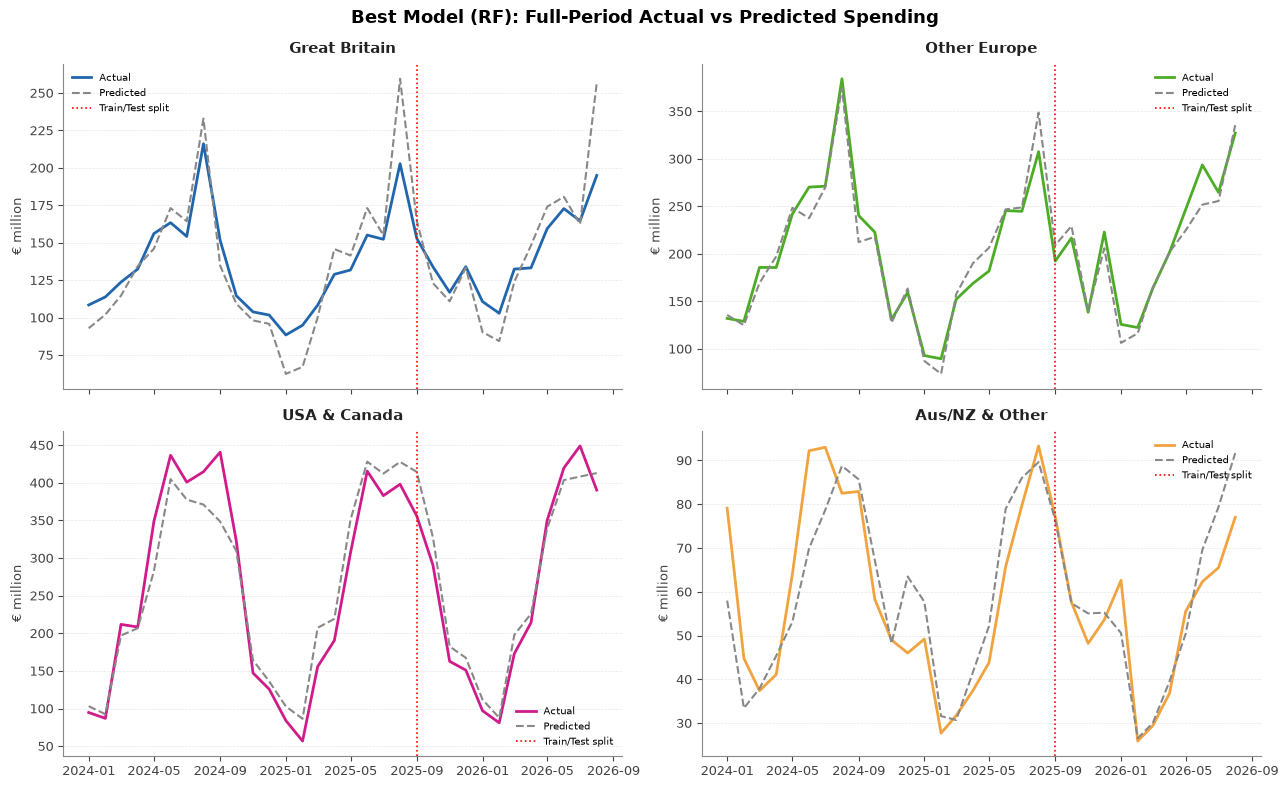

In [66]:
# one dot per group: x = total spend across all months, y = mean spend per trip
# answers RQ1 - shows which groups are high-volume vs high value per visitor
rq1 = merged.groupby("group").agg(
    total_spend_eur_m = ("spend_eur_m", "sum"),
    mean_spend_per_trip = ("spend_per_trip_eur", "mean")
).reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
scatter = ax.scatter(
    rq1["total_spend_eur_m"], rq1["mean_spend_per_trip"],
    c=[GROUP_COLORS[g] for g in rq1["group"]],
    s=200, zorder=5, edgecolors="white", linewidths=1.5
)

for _, row in rq1.iterrows():
    ax.annotate(
        GROUP_LABELS[row["group"]],
        (row["total_spend_eur_m"], row["mean_spend_per_trip"]),
        textcoords="offset points", xytext=(10, 5),
        fontsize=9, color=GROUP_COLORS[row["group"]]
    )

style_ax(ax, title="RQ1: Total Spending vs Average Spend Per Trip by Market Group",
         xlabel="Total Spending Jan 2023–Aug 2026 (€ million)", ylabel="Mean Spend Per Trip (€)")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart11_rq1.png"), dpi=120, bbox_inches="tight")
plt.show()
print(rq1.to_string(index=False))

# -- Best model full-period actual vs predicted ----------------------------
full_preds = best_model.predict(model_df[features])
model_df = model_df.copy()
model_df["predicted"] = full_preds

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
axes = axes.flatten()
for i, grp in enumerate(["XB", "OTHEUR3", "USCA", "OTHR1"]):
    sub = model_df[model_df["group"] == grp].sort_values("date")
    ax = axes[i]
    ax.plot(sub["date"], sub["spend_eur_m"], color=GROUP_COLORS[grp], linewidth=2,
            label="Actual")
    ax.plot(sub["date"], sub["predicted"], color="#888888", linewidth=1.5,
            linestyle="--", label="Predicted")
    split_ts = pd.Timestamp("2025-09-01")
    ax.axvline(split_ts, color="red", linestyle=":", linewidth=1.2, label="Train/Test split")
    style_ax(ax, title=GROUP_LABELS[grp], xlabel="", ylabel="€ million")
    ax.legend(fontsize=7, frameon=False)

fig.suptitle("Best Model (RF): Full-Period Actual vs Predicted Spending", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "chart12_full_period.png"), dpi=120, bbox_inches="tight")
plt.show()


## Section 10 — Conclusions and Recommendations

### Research Question Answers

**RQ1 — Which markets generate the most spending, in total and per trip?**
USA & Canada (USCA) generates the highest total spending over the full analysis period (approximately €11,142 million across 44 months), driven by high per-trip expenditure (mean ≈ €1,988) rather than trip volume. Great Britain (XB) ranks third in total spend (approximately €5,907 million) despite having the largest trip volume, because its spend per trip is the lowest of all groups (mean ≈ €651) — reflecting predominantly short, proximity-driven visits. Aus/NZ & Other (OTHR1) records the highest mean spend per trip (≈ €2,038), consistent with long-haul visitors on extended, premium itineraries. Other Europe (OTHEUR3) leads in total trips after GB but occupies a middle position on both total spend and per-trip value. The key implication for Irish tourism strategy is a dual focus: sustaining GB's large trip volume while investing in premium positioning for USCA and OTHR1.

**RQ2 — How do trips and spending vary by season, and how did 2024→2025 change?**
Market groups peak at different times: USA & Canada peaks in June, Other Europe and Great Britain peak in July–August, and Aus/NZ & Other peaks in August–September. USA & Canada has the steepest seasonal curve, with winter months (January–February) representing a very small fraction of peak-month spending; the gradient for GB is far flatter, and GB shows no secondary October peak. From 2024 to 2025, **all four groups recorded total spending declines**: Aus/NZ & Other −13.7%, Other Europe −11.7%, USA & Canada −8.9%, and Great Britain −2.4%. Great Britain held up best, but the consistent declines across all markets suggest a broad demand-side headwind in 2025 — inconsistent with a simple post-pandemic recovery narrative — rather than any single market-specific problem.

**RQ3 — Can a regression model outperform the "same month last year" baseline?**
Yes. The naive baseline (spend_lag12) achieves a test MAE of approximately 21 €m and R² ≈ 0.93 — a strong benchmark given the persistence of year-on-year spending patterns. Ridge achieves a test MAE of approximately 14.2 €m and R² ≈ 0.96 — about 33% lower error than the naive baseline (21.1 €m). Ridge does not overfit: its test MAE is lower than its train MAE, and the best regularisation alpha is very small (near plain OLS), meaning the dataset is well-conditioned for linear regression. Random Forest approximately matches the baseline (test MAE ≈ 20.7 €m) and does not improve upon it. Ridge is selected as the best model by cross-validation score (CV MAE ≈ 24.3 vs RF 46.5 €m). The finding that a simple linear model beats a Random Forest on this small dataset (80 training rows) is consistent with the statistical literature: tree-based methods need larger samples to learn non-linear structure worth their added complexity.

### Recommendations for Tourism Ireland

1. **Deploy the Ridge model in planning cycles:** Ridge regression reduces forecast error by ~33% versus the naive lag baseline. Integrating monthly group-level forecasts into Tourism Ireland’s budgeting process would allow earlier identification of shortfalls and more targeted promotional spend allocation.
2. **Invest in USCA premium positioning:** USA & Canada generates the most total spending. Targeted premium campaigns (direct flight connectivity, luxury accommodation partnerships, multi-day cultural itineraries) should yield strong revenue per marketing euro.
3. **Prioritise long-haul yield management:** Aus/NZ & Other achieves the highest individual spend per trip. Even modest growth in long-haul visitor volume produces disproportionate revenue gains.
4. **Shore up GB volume:** GB's dominant trip count means any further decline is materially costly. Exchange-rate-adjusted pricing strategies and direct regional air/sea connectivity should be maintained to prevent continued erosion of the largest single source market.
5. **Investigate the 2025 decline across all markets:** The universal spending fall warrants further analysis. Contributing factors may include global economic uncertainty, exchange rate movements, or competition from other European destinations post-pandemic reopening.
6. **Develop shoulder-season products targeting USCA:** USA & Canada has the steepest seasonal curve. Off-peak incentives (festival programming, reduced-rate accommodation in October–November) could smooth demand and reduce infrastructure underutilisation.

### Limitations

- **Data granularity:** CSO publishes only four residency groups; sub-market analysis (e.g. separating German from French visitors) requires the raw 13-market ITM02 series without a corresponding ITM06 counterpart.
- **Short panel:** 44 months is sufficient for seasonal modelling but limits the power of annual trend tests and means the test set contains relatively few observations per group.
- **No external variables:** Exchange rates, airline seat capacity, and macroeconomic indicators are absent from the model, limiting causal inference.
- **Expenditure estimation:** ITM06 figures are survey-based estimates; measurement error propagates into per-trip figures.

### Future Work

- Incorporate exchange rate indices (EUR/GBP, EUR/USD) and consumer confidence indicators as exogenous features.
- Extend to sub-market level using ITM02 trip data as an indirect allocation key.
- Apply seasonal decomposition (STL) to separate trend, seasonality, and residual before modelling.
- Explore Gradient Boosting (XGBoost/LightGBM) and LSTM-based time-series models as the data panel grows.

## Section 11 — References

Central Statistics Office (CSO) (2026) *International Travel and Migration: ITM02 — Trips by Foreign Resident Overnight Visitors*, CSO Ireland. Available at: https://data.cso.ie/table/ITM02 (Accessed: October 2026).

Central Statistics Office (CSO) (2026) *International Travel and Migration: ITM06 — Expenditure of Foreign Resident Overnight Visitors*, CSO Ireland. Available at: https://data.cso.ie/table/ITM06 (Accessed: October 2026).

Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C. and Wirth, R. (2000) *CRISP-DM 1.0 Step-by-step data mining guide*. SPSS Inc.

Fayyad, U., Piatetsky-Shapiro, G. and Smyth, P. (1996) 'From data mining to knowledge discovery in databases', *AI Magazine*, 17(3), pp. 37–54.

Hastie, T., Tibshirani, R. and Friedman, J. (2009) *The Elements of Statistical Learning*. 2nd edn. New York: Springer.

Hoerl, A.E. and Kennard, R.W. (1970) 'Ridge regression: Biased estimation for nonorthogonal problems', *Technometrics*, 12(1), pp. 55–67.

McKinney, W. (2010) 'Data structures for statistical computing in Python', in *Proceedings of the 9th Python in Science Conference*, pp. 51–56.

Pedregosa, F. et al. (2011) 'Scikit-learn: Machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830.

Shapiro, S.S. and Wilk, M.B. (1965) 'An analysis of variance test for normality (complete samples)', *Biometrika*, 52(3–4), pp. 591–611.

SAS Institute (1999) *SEMMA methodology*. Cary, NC: SAS Institute Inc.

Tufte, E.R. (2001) *The Visual Display of Quantitative Information*. 2nd edn. Cheshire, CT: Graphics Press.

Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5–32.

Hunter, J.D. (2007) 'Matplotlib: A 2D graphics environment', *Computing in Science & Engineering*, 9(3), pp. 90–95.

Virtanen, P. et al. (2020) 'SciPy 1.0: Fundamental algorithms for scientific computing in Python', *Nature Methods*, 17(3), pp. 261–272.